# Macro event surprise DataFrame

This notebook converts the event-level actual, consensus expectation, and surprise results into modeling-ready pandas DataFrames.

- `surprise_long`: one row per event and metric.
- `surprise_df`: one row per event and reference period, with separate fields such as `headline_yoy_actual`, `headline_yoy_expected`, and `headline_yoy_surprise`.
- `expectation_phase` distinguishes a genuine pre-release expectation (`pre`) from a consensus restated after the release (`post`).
- Surprise is defined as **actual minus expected**. For percentage metrics it is measured in percentage points; payroll surprises are measured in jobs; policy-rate changes are measured in basis points.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 180)

In [2]:
def find_project_root(start: Path) -> Path:
    required = Path("outputs/macro_event_identification/event_metrics_actual_vs_expected.csv")
    for directory in (start.resolve(), *start.resolve().parents):
        if (directory / required).exists():
            return directory
    raise FileNotFoundError(f"Could not find {required} from {start.resolve()}")

ROOT = find_project_root(Path.cwd())
DATA_DIR = ROOT / "outputs" / "macro_event_identification"
METRICS_PATH = DATA_DIR / "event_metrics_actual_vs_expected.csv"
EVENTS_PATH = DATA_DIR / "macro_events.csv"
OUTPUT_PATH = DATA_DIR / "macro_event_surprises_wide.csv"
DAILY_OUTPUT_PATH = DATA_DIR / "macro_event_surprises_by_release_date.csv"

ROOT

WindowsPath('C:/Users/Jerry Cai/Desktop/NLP_Final_Assignment')

In [3]:
metrics = pd.read_csv(METRICS_PATH)
events = pd.read_csv(EVENTS_PATH)

numeric_columns = ["actual_value", "expected_value", "surprise"]
metrics[numeric_columns] = metrics[numeric_columns].apply(pd.to_numeric, errors="coerce")

datetime_columns = ["official_release_datetime_et", "earliest_news_datetime_et"]
for column in datetime_columns:
    events[column] = pd.to_datetime(events[column], errors="coerce")
metrics["expectation_news_datetime_et"] = pd.to_datetime(
    metrics["expectation_news_datetime_et"], errors="coerce"
)

print(f"Loaded {len(events):,} events and {len(metrics):,} event-metric rows.")

Loaded 43 events and 134 event-metric rows.


## Long-form DataFrame

The long form is convenient for regressions with metric fixed effects, filtering, and plotting. Missing expectations remain `NaN`; they are not replaced with zero.

In [4]:
surprise_long = metrics[[
    "event_id",
    "event_type",
    "reference_period",
    "metric",
    "unit",
    "actual_value",
    "expected_value",
    "surprise",
    "expectation_observation_phase",
    "expectation_source",
    "expectation_news_datetime_et",
    "expectation_news_url",
    "actual_source_basis",
]].copy()

surprise_long = surprise_long.rename(columns={
    "expectation_observation_phase": "expectation_phase",
})

comparable = surprise_long["actual_value"].notna() & surprise_long["expected_value"].notna()
assert np.allclose(
    surprise_long.loc[comparable, "surprise"],
    surprise_long.loc[comparable, "actual_value"] - surprise_long.loc[comparable, "expected_value"],
    equal_nan=True,
)

surprise_long.head(10)

,event_id,event_type,reference_period,metric,unit,actual_value,expected_value,surprise,expectation_phase,expectation_source,expectation_news_datetime_et,expectation_news_url,actual_source_basis
0,CPI_2025-09,CPI_RELEASE,2025-09,headline_yoy,percent,3.0,3.1,-0.1,post,Dow Jones consensus estimate,2025-10-24 08:31:04,https://www.cnbc.com/2025/10/24/cpi-inflation-...,result_news
1,CPI_2025-09,CPI_RELEASE,2025-09,headline_mom,percent,0.3,0.4,-0.1,post,Dow Jones survey,2025-10-24 09:27:49,https://invezz.com/news/2025/10/24/us-inflatio...,result_news
2,CPI_2025-09,CPI_RELEASE,2025-09,core_mom,percent,0.2,NaN,NaN,NaN,NaN,NaT,NaN,result_news
3,CPI_2025-11,CPI_RELEASE,2025-11,headline_yoy,percent,2.7,3.1,-0.4,post,Economists polled by Dow Jones,2025-12-18 08:31:28,https://www.cnbc.com/2025/12/18/cpi-inflation-...,result_news
4,CPI_2025-11,CPI_RELEASE,2025-11,core_yoy,percent,2.6,3.0,-0.4,post,forecast,2025-12-18 10:36:22,https://www.proactiveinvestors.com/companies/n...,result_news
5,CPI_2025-12,CPI_RELEASE,2025-12,headline_yoy,percent,2.7,2.7,0.0,pre,Analysts expect,2026-01-09 09:05:24,https://www.forbes.com/sites/tylerroush/2026/0...,result_news
6,CPI_2025-12,CPI_RELEASE,2025-12,core_yoy,percent,2.6,2.7,-0.1,pre,Analysts expect,2026-01-09 09:05:24,https://www.forbes.com/sites/tylerroush/2026/0...,result_news
7,CPI_2025-12,CPI_RELEASE,2025-12,core_mom,percent,0.2,0.3,-0.1,pre,forecast,2026-01-11 14:28:40,https://seekingalpha.com/article/4858659-wall-...,result_news
8,CPI_2026-01,CPI_RELEASE,2026-01,headline_yoy,percent,2.4,2.5,-0.1,pre,CNBC,2026-02-12 14:55:30,https://www.cnbc.com/2026/02/12/the-january-cp...,result_news
9,CPI_2026-01,CPI_RELEASE,2026-01,headline_mom,percent,0.2,NaN,NaN,NaN,NaN,NaT,NaN,result_news


## Wide event-level DataFrame

Each metric is split into separate actual, expected, surprise, unit, and expectation-phase fields. The unique key is `event_id + reference_period`, so a release covering two reference months retains both observations.

In [5]:
metric_order = [
    "headline_yoy",
    "headline_mom",
    "core_yoy",
    "core_mom",
    "unemployment_rate",
    "nonfarm_payroll_change",
    "target_lower",
    "target_upper",
    "rate_change_bps",
]

value_columns = {
    "actual_value": "actual",
    "expected_value": "expected",
    "surprise": "surprise",
    "unit": "unit",
    "expectation_phase": "expectation_phase",
}

wide_parts = []
for metric_name in metric_order:
    metric_rows = (
        surprise_long.loc[surprise_long["metric"].eq(metric_name), ["event_id", "reference_period", *value_columns]]
        .drop_duplicates(subset=["event_id", "reference_period"], keep="first")
        .set_index(["event_id", "reference_period"])
        .rename(columns={source: f"{metric_name}_{suffix}" for source, suffix in value_columns.items()})
    )
    wide_parts.append(metric_rows)

metric_wide = pd.concat(wide_parts, axis=1).reset_index()

event_columns = [
    "event_id",
    "event_type",
    "official_release_datetime_et",
    "earliest_news_datetime_et",
    "publication_lag_minutes",
    "earliest_publisher",
    "earliest_title",
    "earliest_news_url",
]

surprise_df = (
    metric_wide
    .merge(events[event_columns], on="event_id", how="left", validate="many_to_one")
    .sort_values(["official_release_datetime_et", "reference_period"])
    .reset_index(drop=True)
)

metadata_columns = ["event_id", "event_type", "reference_period", "official_release_datetime_et", "earliest_news_datetime_et", "publication_lag_minutes", "earliest_publisher", "earliest_title", "earliest_news_url"]
surprise_df = surprise_df[metadata_columns + [column for column in surprise_df if column not in metadata_columns]]

assert not surprise_df.duplicated(["event_id", "reference_period"]).any()
print(f"surprise_df shape: {surprise_df.shape}")
surprise_df.head()

surprise_df shape: (44, 54)


,event_id,event_type,reference_period,official_release_datetime_et,earliest_news_datetime_et,publication_lag_minutes,earliest_publisher,earliest_title,earliest_news_url,headline_yoy_actual,headline_yoy_expected,headline_yoy_surprise,headline_yoy_unit,headline_yoy_expectation_phase,headline_mom_actual,headline_mom_expected,headline_mom_surprise,headline_mom_unit,headline_mom_expectation_phase,core_yoy_actual,core_yoy_expected,core_yoy_surprise,core_yoy_unit,core_yoy_expectation_phase,core_mom_actual,core_mom_expected,core_mom_surprise,core_mom_unit,core_mom_expectation_phase,unemployment_rate_actual,unemployment_rate_expected,unemployment_rate_surprise,unemployment_rate_unit,unemployment_rate_expectation_phase,nonfarm_payroll_change_actual,nonfarm_payroll_change_expected,nonfarm_payroll_change_surprise,nonfarm_payroll_change_unit,nonfarm_payroll_change_expectation_phase,target_lower_actual,target_lower_expected,target_lower_surprise,target_lower_unit,target_lower_expectation_phase,target_upper_actual,target_upper_expected,target_upper_surprise,target_upper_unit,target_upper_expectation_phase,rate_change_bps_actual,rate_change_bps_expected,rate_change_bps_surprise,rate_change_bps_unit,rate_change_bps_expectation_phase
0,CPI_2025-09,CPI_RELEASE,2025-09,2025-10-24 08:30:00,2025-10-24 08:31:04,1.07,CNBC,"Inflation rate hit 3.0% in September, lower th...",https://www.cnbc.com/2025/10/24/cpi-inflation-...,3.0,3.1,-0.1,percent,post,0.3,0.4,-0.1,percent,post,NaN,NaN,NaN,NaN,NaN,0.2,NaN,NaN,percent,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,FOMC_2025-10-29,FOMC_RATE_DECISION,2025-10-29,2025-10-29 14:00:00,2025-10-29 14:00:16,0.27,Business Insider,The Fed announces its second rate cut of the y...,https://www.businessinsider.com/fed-cuts-rates...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.75,NaN,NaN,percent,NaN,4.00,NaN,NaN,percent,NaN,-25.0,-25.0,0.0,basis_points,pre
2,EMPLOYMENT_2025-09,EMPLOYMENT_RELEASE,2025-09,2025-11-20 08:30:00,2025-11-20 08:31:03,1.05,CNBC,Delayed September report shows U.S. economy ad...,https://www.cnbc.com/2025/11/20/jobs-report-se...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.4,NaN,NaN,percent,NaN,119000.0,50000.0,69000.0,jobs,post,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,PCE_2025-09,PCE_RELEASE,2025-09,2025-12-05 10:00:00,2025-12-05 10:36:00,36.00,Fox Business,Fed's favored inflation gauge shows consumer p...,https://www.foxbusiness.com/economy/september-...,2.8,NaN,NaN,percent,NaN,0.3,NaN,NaN,percent,NaN,2.8,NaN,NaN,percent,NaN,0.2,NaN,NaN,percent,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,FOMC_2025-12-10,FOMC_RATE_DECISION,2025-12-10,2025-12-10 14:00:00,2025-12-10 14:00:51,0.85,CNBC,"Divided Fed approves third rate cut, sees slow...",https://www.cnbc.com/2025/12/10/fed-interest-r...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.50,3.5,0.0,percent,pre,3.75,3.75,0.0,percent,pre,-25.0,-25.0,0.0,basis_points,pre


## Modeling subsets

Use `pre_release_surprise_df` for a strict ex-ante event study. `all_available_surprise_df` also keeps surprise fields whose consensus was only observed in a post-release article.

## Aggregate surprises by official release date

Raw payroll surprises, percentage-point surprises, and basis-point surprises are not directly comparable. The composite event surprise therefore scales each metric by its own sample standard deviation and then averages all available standardized surprises released on the same date. Zero-variance metrics whose observed surprises are all zero contribute zero.

`event_surprise_mean` uses all available expectations and is measured in standard-deviation units (dimensionless z-score average). `event_surprise_pre_mean` uses only expectations observed before the release and has the same unit. `equity_direction_score` reorients each metric so positive values are conventionally favorable for broad U.S. equities. The label describes the macro signal, not the realized stock return.

In [6]:
release_times = events[["event_id", "official_release_datetime_et"]].drop_duplicates("event_id")
event_components = surprise_long.merge(release_times, on="event_id", how="left", validate="many_to_one")
event_components = event_components.loc[event_components["surprise"].notna()].copy()
event_components["release_date"] = event_components["official_release_datetime_et"].dt.normalize()

metric_scales = event_components.groupby("metric")["surprise"].std(ddof=1)
event_components["metric_surprise_scale"] = event_components["metric"].map(metric_scales)
positive_scale = event_components["metric_surprise_scale"].gt(0)
event_components["standardized_surprise"] = np.where(
    positive_scale,
    event_components["surprise"] / event_components["metric_surprise_scale"],
    0.0,
)
EQUITY_DIRECTION_SIGN = {
    "headline_yoy": -1.0,
    "headline_mom": -1.0,
    "core_yoy": -1.0,
    "core_mom": -1.0,
    "unemployment_rate": -1.0,
    "nonfarm_payroll_change": 1.0,
    "target_lower": -1.0,
    "target_upper": -1.0,
    "rate_change_bps": -1.0,
}
event_components["equity_direction_sign"] = event_components["metric"].map(EQUITY_DIRECTION_SIGN)
event_components["equity_direction_component"] = (
    event_components["standardized_surprise"] * event_components["equity_direction_sign"]
)
event_components["is_pre"] = event_components["expectation_phase"].eq("pre")
event_components["surprise_pp"] = event_components["surprise"].where(event_components["unit"].eq("percent"))
event_components["surprise_jobs"] = event_components["surprise"].where(event_components["unit"].eq("jobs"))
event_components["surprise_thousand_jobs"] = event_components["surprise"].where(event_components["unit"].eq("thousand_jobs"))
event_components["surprise_bps"] = event_components["surprise"].where(event_components["unit"].eq("basis_points"))

def join_unique(values):
    return " | ".join(sorted(set(values.dropna().astype(str))))

daily_event_df = (
    event_components.groupby("release_date", as_index=False)
    .agg(
        event_surprise_mean=("standardized_surprise", "mean"),
        equity_direction_score=("equity_direction_component", "mean"),
        surprise_count=("surprise", "size"),
        pre_surprise_count=("is_pre", "sum"),
        official_release_count=("event_id", "nunique"),
        event_ids=("event_id", join_unique),
        event_types=("event_type", join_unique),
        raw_mean_percentage_points=("surprise_pp", "mean"),
        raw_mean_jobs=("surprise_jobs", "mean"),
        raw_mean_thousand_jobs=("surprise_thousand_jobs", "mean"),
        raw_mean_basis_points=("surprise_bps", "mean"),
    )
)
daily_event_df["post_surprise_count"] = daily_event_df["surprise_count"] - daily_event_df["pre_surprise_count"]

daily_pre = (
    event_components.loc[event_components["is_pre"]]
    .groupby("release_date", as_index=False)
    .agg(
        event_surprise_pre_mean=("standardized_surprise", "mean"),
        equity_direction_pre_score=("equity_direction_component", "mean"),
    )
)
daily_event_df = daily_event_df.merge(daily_pre, on="release_date", how="left", validate="one_to_one")

release_scaffold = events.assign(
    release_date=events["official_release_datetime_et"].dt.normalize()
).groupby("release_date", as_index=False).agg(
    official_release_datetime_et=("official_release_datetime_et", "min"),
    earliest_news_datetime_et=("earliest_news_datetime_et", "min"),
    earliest_news_lag_minutes=("publication_lag_minutes", "min"),
    official_release_count=("event_id", "nunique"),
    event_ids=("event_id", join_unique),
    event_types=("event_type", join_unique),
)
daily_event_df = (
    release_scaffold.merge(
        daily_event_df.drop(columns=["official_release_count", "event_ids", "event_types"]),
        on="release_date",
        how="left",
        validate="one_to_one",
    )
    .sort_values("release_date")
    .reset_index(drop=True)
)
for count_column in ["surprise_count", "pre_surprise_count", "post_surprise_count"]:
    daily_event_df[count_column] = daily_event_df[count_column].fillna(0).astype(int)
daily_event_df["event_surprise_unit"] = "standard deviations"
EQUITY_LABEL_THRESHOLD = 0.10
def equity_label(score):
    if pd.isna(score):
        return "无法判断"
    if score > EQUITY_LABEL_THRESHOLD:
        return "利好"
    if score < -EQUITY_LABEL_THRESHOLD:
        return "利空"
    return "中性"

daily_event_df["equity_label"] = daily_event_df["equity_direction_score"].map(equity_label)
daily_event_df["equity_label_pre"] = daily_event_df["equity_direction_pre_score"].map(equity_label)
daily_event_df["equity_label_basis"] = "conventional broad U.S. equity interpretation"
daily_event_df = daily_event_df[[
    "release_date", "official_release_datetime_et", "earliest_news_datetime_et",
    "earliest_news_lag_minutes", "official_release_count", "event_ids", "event_types",
    "event_surprise_mean", "event_surprise_pre_mean", "event_surprise_unit",
    "equity_direction_score", "equity_label",
    "equity_direction_pre_score", "equity_label_pre", "equity_label_basis",
    "surprise_count", "pre_surprise_count", "post_surprise_count",
    "raw_mean_percentage_points", "raw_mean_jobs",
    "raw_mean_thousand_jobs", "raw_mean_basis_points",
]]

daily_event_df.head(10)

,release_date,official_release_datetime_et,earliest_news_datetime_et,earliest_news_lag_minutes,official_release_count,event_ids,event_types,event_surprise_mean,event_surprise_pre_mean,event_surprise_unit,equity_direction_score,equity_label,equity_direction_pre_score,equity_label_pre,equity_label_basis,surprise_count,pre_surprise_count,post_surprise_count,raw_mean_percentage_points,raw_mean_jobs,raw_mean_thousand_jobs,raw_mean_basis_points
0,2025-10-24,2025-10-24 08:30:00,2025-10-24 08:31:04,1.07,1,CPI_2025-09,CPI_RELEASE,-1.188774,NaN,standard deviations,1.188774,利好,NaN,无法判断,conventional broad U.S. equity interpretation,2,0,2,-0.100000,NaN,NaN,NaN
1,2025-10-29,2025-10-29 14:00:00,2025-10-29 14:00:16,0.27,1,FOMC_2025-10-29,FOMC_RATE_DECISION,0.000000,0.000000,standard deviations,0.000000,中性,0.000000,中性,conventional broad U.S. equity interpretation,1,1,0,NaN,NaN,NaN,0.0
2,2025-11-20,2025-11-20 08:30:00,2025-11-20 08:31:03,1.05,1,EMPLOYMENT_2025-09,EMPLOYMENT_RELEASE,0.911475,NaN,standard deviations,0.911475,利好,NaN,无法判断,conventional broad U.S. equity interpretation,1,0,1,NaN,69000.0,NaN,NaN
3,2025-12-05,2025-12-05 10:00:00,2025-12-05 10:36:00,36.00,1,PCE_2025-09,PCE_RELEASE,NaN,NaN,standard deviations,NaN,无法判断,NaN,无法判断,conventional broad U.S. equity interpretation,0,0,0,NaN,NaN,NaN,NaN
4,2025-12-10,2025-12-10 14:00:00,2025-12-10 14:00:51,0.85,1,FOMC_2025-12-10,FOMC_RATE_DECISION,0.000000,0.000000,standard deviations,0.000000,中性,0.000000,中性,conventional broad U.S. equity interpretation,3,3,0,0.000000,NaN,NaN,0.0
5,2025-12-16,2025-12-16 08:30:00,2025-12-16 08:32:01,2.02,1,EMPLOYMENT_2025-11,EMPLOYMENT_RELEASE,0.669600,NaN,standard deviations,-0.418614,利空,NaN,无法判断,conventional broad U.S. equity interpretation,2,0,2,0.100000,19000.0,NaN,NaN
6,2025-12-18,2025-12-18 08:30:00,2025-12-18 08:31:28,1.47,1,CPI_2025-11,CPI_RELEASE,-2.613870,NaN,standard deviations,2.613870,利好,NaN,无法判断,conventional broad U.S. equity interpretation,2,0,2,-0.400000,NaN,NaN,NaN
7,2026-01-09,2026-01-09 08:30:00,2026-01-09 08:31:00,1.00,1,EMPLOYMENT_2025-12,EMPLOYMENT_RELEASE,-0.696020,-0.696020,standard deviations,0.392195,利好,0.392195,利好,conventional broad U.S. equity interpretation,2,2,0,-0.100000,-23000.0,NaN,NaN
8,2026-01-13,2026-01-13 08:30:00,2026-01-13 08:34:00,4.00,1,CPI_2025-12,CPI_RELEASE,-0.559511,-0.559511,standard deviations,0.559511,利好,0.559511,利好,conventional broad U.S. equity interpretation,3,3,0,-0.066667,NaN,NaN,NaN
9,2026-01-22,2026-01-22 10:00:00,2026-01-22 10:13:00,13.00,1,PCE_2025-10_2025-11,PCE_RELEASE,0.000000,0.000000,standard deviations,0.000000,中性,0.000000,中性,conventional broad U.S. equity interpretation,1,1,0,0.000000,NaN,NaN,NaN


In [7]:
phase_columns = [column for column in surprise_df if column.endswith("_expectation_phase")]
surprise_columns = [column for column in surprise_df if column.endswith("_surprise")]

pre_release_surprise_df = surprise_df.copy()
for phase_column in phase_columns:
    metric_prefix = phase_column.removesuffix("_expectation_phase")
    not_pre = pre_release_surprise_df[phase_column].ne("pre")
    pre_release_surprise_df.loc[not_pre, f"{metric_prefix}_expected"] = np.nan
    pre_release_surprise_df.loc[not_pre, f"{metric_prefix}_surprise"] = np.nan

all_available_surprise_df = surprise_df.copy()

print("Comparable surprise observations (all available):", int(all_available_surprise_df[surprise_columns].notna().sum().sum()))
print("Comparable surprise observations (pre-release only):", int(pre_release_surprise_df[surprise_columns].notna().sum().sum()))

Comparable surprise observations (all available): 70
Comparable surprise observations (pre-release only): 47


In [8]:
surprise_df.to_csv(OUTPUT_PATH, index=False)
daily_event_df.to_csv(DAILY_OUTPUT_PATH, index=False)
print(f"Saved wide event-level data to: {OUTPUT_PATH}")
print(f"Saved release-date event data to: {DAILY_OUTPUT_PATH}")

Saved wide event-level data to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\macro_event_surprises_wide.csv
Saved release-date event data to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\macro_event_surprises_by_release_date.csv


## Final aggregated event DataFrame

`daily_event_df` is the final dataset with one row per official release date.

In [9]:
daily_event_df

,release_date,official_release_datetime_et,earliest_news_datetime_et,earliest_news_lag_minutes,official_release_count,event_ids,event_types,event_surprise_mean,event_surprise_pre_mean,event_surprise_unit,equity_direction_score,equity_label,equity_direction_pre_score,equity_label_pre,equity_label_basis,surprise_count,pre_surprise_count,post_surprise_count,raw_mean_percentage_points,raw_mean_jobs,raw_mean_thousand_jobs,raw_mean_basis_points
0,2025-10-24,2025-10-24 08:30:00,2025-10-24 08:31:04,1.07,1,CPI_2025-09,CPI_RELEASE,-1.188774,NaN,standard deviations,1.188774,利好,NaN,无法判断,conventional broad U.S. equity interpretation,2,0,2,-0.100000,NaN,NaN,NaN
1,2025-10-29,2025-10-29 14:00:00,2025-10-29 14:00:16,0.27,1,FOMC_2025-10-29,FOMC_RATE_DECISION,0.000000,0.000000,standard deviations,0.000000,中性,0.000000,中性,conventional broad U.S. equity interpretation,1,1,0,NaN,NaN,NaN,0.0
2,2025-11-20,2025-11-20 08:30:00,2025-11-20 08:31:03,1.05,1,EMPLOYMENT_2025-09,EMPLOYMENT_RELEASE,0.911475,NaN,standard deviations,0.911475,利好,NaN,无法判断,conventional broad U.S. equity interpretation,1,0,1,NaN,69000.0,NaN,NaN
3,2025-12-05,2025-12-05 10:00:00,2025-12-05 10:36:00,36.00,1,PCE_2025-09,PCE_RELEASE,NaN,NaN,standard deviations,NaN,无法判断,NaN,无法判断,conventional broad U.S. equity interpretation,0,0,0,NaN,NaN,NaN,NaN
4,2025-12-10,2025-12-10 14:00:00,2025-12-10 14:00:51,0.85,1,FOMC_2025-12-10,FOMC_RATE_DECISION,0.000000,0.000000,standard deviations,0.000000,中性,0.000000,中性,conventional broad U.S. equity interpretation,3,3,0,0.000000,NaN,NaN,0.0
5,2025-12-16,2025-12-16 08:30:00,2025-12-16 08:32:01,2.02,1,EMPLOYMENT_2025-11,EMPLOYMENT_RELEASE,0.669600,NaN,standard deviations,-0.418614,利空,NaN,无法判断,conventional broad U.S. equity interpretation,2,0,2,0.100000,19000.0,NaN,NaN
6,2025-12-18,2025-12-18 08:30:00,2025-12-18 08:31:28,1.47,1,CPI_2025-11,CPI_RELEASE,-2.613870,NaN,standard deviations,2.613870,利好,NaN,无法判断,conventional broad U.S. equity interpretation,2,0,2,-0.400000,NaN,NaN,NaN
7,2026-01-09,2026-01-09 08:30:00,2026-01-09 08:31:00,1.00,1,EMPLOYMENT_2025-12,EMPLOYMENT_RELEASE,-0.696020,-0.696020,standard deviations,0.392195,利好,0.392195,利好,conventional broad U.S. equity interpretation,2,2,0,-0.100000,-23000.0,NaN,NaN
8,2026-01-13,2026-01-13 08:30:00,2026-01-13 08:34:00,4.00,1,CPI_2025-12,CPI_RELEASE,-0.559511,-0.559511,standard deviations,0.559511,利好,0.559511,利好,conventional broad U.S. equity interpretation,3,3,0,-0.066667,NaN,NaN,NaN
9,2026-01-22,2026-01-22 10:00:00,2026-01-22 10:13:00,13.00,1,PCE_2025-10_2025-11,PCE_RELEASE,0.000000,0.000000,standard deviations,0.000000,中性,0.000000,中性,conventional broad U.S. equity interpretation,1,1,0,0.000000,NaN,NaN,NaN


## Regular-session three-day QQQ path (descriptive, not news-aligned)

**Legacy descriptive view:** this section contains only 09:30–16:00 ET bars and aligns events by the event-day open, not by the news timestamp. Do not interpret these figures as the immediate response to a release. The corrected extended-hours, news-centered event study appears at the end of this notebook. Events labelled `无法判断` are not downloaded.

Return fields include the close-to-close one-minute return, the within-session return from the opening price, and the cumulative return from the close of `T-1`. `minutes_from_earliest_news` uses the earliest identified news timestamp as time zero.

In [10]:
import subprocess
import sys

SYMBOL = "QQQ"
INTRADAY_PATH = DATA_DIR / f"{SYMBOL}_event_intraday_1min.csv"
INTRADAY_SUMMARY_PATH = DATA_DIR / f"{SYMBOL}_event_intraday_summary.csv"

# Download only if the saved result is absent. API responses are cached by trading day.
if not INTRADAY_PATH.exists():
    subprocess.run(
        [sys.executable, str(ROOT / "scripts" / "download_event_intraday_fmp.py"), "--symbol", SYMBOL],
        check=True,
    )

minute_returns_df = pd.read_csv(INTRADAY_PATH)
event_intraday_summary_df = pd.read_csv(INTRADAY_SUMMARY_PATH)
minute_returns_df["release_date"] = pd.to_datetime(minute_returns_df["release_date"])
minute_returns_df["trading_date"] = pd.to_datetime(minute_returns_df["trading_date"])
for column in ["datetime_et", "official_release_datetime_et", "earliest_news_datetime_et"]:
    minute_returns_df[column] = pd.to_datetime(minute_returns_df[column], utc=True, errors="coerce").dt.tz_convert("America/New_York")

print(f"Loaded {len(minute_returns_df):,} QQQ minute bars for {minute_returns_df['release_date'].nunique()} identifiable events.")
print(minute_returns_df.groupby('session_role', observed=True).size().reindex(['T-1', 'T', 'T+1']))

Loaded 42,120 QQQ minute bars for 36 identifiable events.
session_role
T-1    14040
T      14040
T+1    14040
dtype: int64


### Minute-return field definitions

- `price_change`: current minute close minus the preceding minute close, in QQQ dollars; the 09:30 bar uses that bar's open.
- `minute_return`: close-to-close decimal return (09:30 close versus 09:30 open); `minute_return_pct` is the same return in percent.
- `log_return`: one-minute log return.
- `session_return_from_open_pct`: cumulative percent return from that session's first-minute open.
- `return_from_pre_event_close_pct`: cumulative percent return relative to the last close on `T-1`.
- `minutes_from_earliest_news`: signed minutes relative to the earliest identified event news.

In [11]:
display(event_intraday_summary_df)
minute_returns_df.head(10)

,release_date,event_ids,event_types,equity_label,symbol,status,message,t_minus_1_date,event_trading_date,t_plus_1_date,minute_rows
0,2025-10-24,CPI_2025-09,CPI_RELEASE,利好,QQQ,ok,NaN,2025-10-23,2025-10-24,2025-10-27,1170
1,2025-10-29,FOMC_2025-10-29,FOMC_RATE_DECISION,中性,QQQ,ok,NaN,2025-10-28,2025-10-29,2025-10-30,1170
2,2025-11-20,EMPLOYMENT_2025-09,EMPLOYMENT_RELEASE,利好,QQQ,ok,NaN,2025-11-19,2025-11-20,2025-11-21,1170
3,2025-12-10,FOMC_2025-12-10,FOMC_RATE_DECISION,中性,QQQ,ok,NaN,2025-12-09,2025-12-10,2025-12-11,1170
4,2025-12-16,EMPLOYMENT_2025-11,EMPLOYMENT_RELEASE,利空,QQQ,ok,NaN,2025-12-15,2025-12-16,2025-12-17,1170
5,2025-12-18,CPI_2025-11,CPI_RELEASE,利好,QQQ,ok,NaN,2025-12-17,2025-12-18,2025-12-19,1170
6,2026-01-09,EMPLOYMENT_2025-12,EMPLOYMENT_RELEASE,利好,QQQ,ok,NaN,2026-01-08,2026-01-09,2026-01-12,1170
7,2026-01-13,CPI_2025-12,CPI_RELEASE,利好,QQQ,ok,NaN,2026-01-12,2026-01-13,2026-01-14,1170
8,2026-01-22,PCE_2025-10_2025-11,PCE_RELEASE,中性,QQQ,ok,NaN,2026-01-21,2026-01-22,2026-01-23,1170
9,2026-01-28,FOMC_2026-01-28,FOMC_RATE_DECISION,中性,QQQ,ok,NaN,2026-01-27,2026-01-28,2026-01-29,1170


,release_date,event_ids,event_types,official_release_datetime_et,earliest_news_datetime_et,earliest_news_lag_minutes,equity_label,equity_direction_score,equity_label_pre,equity_direction_pre_score,event_surprise_mean,event_surprise_pre_mean,event_surprise_unit,symbol,session_role,trading_date,datetime_et,minutes_from_earliest_news,after_earliest_news,open,high,low,close,volume,price_change,minute_return,minute_return_pct,log_return,session_return_from_open_pct,return_from_pre_event_close_pct,equity_label_basis
0,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:30:00-04:00,-1141.066667,False,604.91,605.34,604.85,605.08,2793729.0,0.17,0.000281,0.028103,0.000281,0.028103,-0.907275,conventional broad U.S. equity interpretation
1,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:31:00-04:00,-1140.066667,False,605.09,605.26,604.52,605.10,298423.0,0.02,0.000033,0.003305,0.000033,0.031410,-0.903999,conventional broad U.S. equity interpretation
2,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:32:00-04:00,-1139.066667,False,605.11,605.51,604.88,605.23,172692.0,0.13,0.000215,0.021484,0.000215,0.052900,-0.882709,conventional broad U.S. equity interpretation
3,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:33:00-04:00,-1138.066667,False,605.26,605.55,604.97,605.46,170436.0,0.23,0.000380,0.038002,0.000380,0.090923,-0.845043,conventional broad U.S. equity interpretation
4,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:34:00-04:00,-1137.066667,False,605.42,605.51,605.09,605.28,128012.0,-0.18,-0.000297,-0.029729,-0.000297,0.061166,-0.874521,conventional broad U.S. equity interpretation
5,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:35:00-04:00,-1136.066667,False,605.30,605.62,604.99,605.58,229393.0,0.30,0.000496,0.049564,0.000496,0.110760,-0.825391,conventional broad U.S. equity interpretation
6,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:36:00-04:00,-1135.066667,False,605.65,606.03,605.46,605.99,167323.0,0.41,0.000677,0.067704,0.000677,0.178539,-0.758246,conventional broad U.S. equity interpretation
7,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:37:00-04:00,-1134.066667,False,605.99,606.17,605.88,605.96,159246.0,-0.03,-0.000050,-0.004951,-0.000050,0.173580,-0.763159,conventional broad U.S. equity interpretation
8,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:38:00-04:00,-1133.066667,False,606.01,606.19,605.91,606.16,159422.0,0.20,0.000330,0.033005,0.000330,0.206642,-0.730405,conventional broad U.S. equity interpretation
9,2025-10-24,CPI_2025-09,CPI_RELEASE,2025-10-24 04:30:00-04:00,2025-10-24 04:31:04-04:00,1.07,利好,1.188774,无法判断,NaN,-1.188774,NaN,standard deviations,QQQ,T-1,2025-10-23,2025-10-23 09:39:00-04:00,-1132.066667,False,606.17,606.40,605.98,606.16,160059.0,0.00,0.000000,0.000000,0.000000,0.206642,-0.730405,conventional broad U.S. equity interpretation


## Regular-session aggregation (legacy descriptive view)

Events are grouped by `event_types × equity_label`, for example `EMPLOYMENT_RELEASE × 利好` and `EMPLOYMENT_RELEASE × 利空`. The three sessions are aligned to a common 1,170-minute event-time grid: `T-1` minutes 0–389, event day `T` minutes 390–779, and `T+1` minutes 780–1,169.

For each group and aligned minute, `mean_minute_return_pct` is the cross-event average QQQ one-minute return. Neutral events are retained as a separate group and are never mixed with bullish or bearish events.

In [12]:
SESSION_ORDER = ["T-1", "T", "T+1"]
SESSION_OFFSET = {"T-1": 0, "T": 390, "T+1": 780}
VALID_EQUITY_LABELS = ["利好", "利空", "中性"]

event_minute_df = minute_returns_df.loc[
    minute_returns_df["equity_label"].isin(VALID_EQUITY_LABELS)
].copy()
event_minute_df["session_role"] = pd.Categorical(
    event_minute_df["session_role"], categories=SESSION_ORDER, ordered=True
)
event_minute_df = event_minute_df.sort_values(
    ["release_date", "session_role", "datetime_et"]
).reset_index(drop=True)
event_minute_df["minute_in_session"] = event_minute_df.groupby(
    ["release_date", "session_role"], observed=True
).cumcount()
event_minute_df["aligned_minute"] = (
    event_minute_df["session_role"].astype("object").map(SESSION_OFFSET).astype(int)
    + event_minute_df["minute_in_session"]
)

event_group_counts = (
    event_minute_df[["release_date", "event_types", "equity_label"]]
    .drop_duplicates()
    .groupby(["event_types", "equity_label"], observed=True)
    .size()
    .rename("event_count")
    .reset_index()
)

event_direction_minute_avg = (
    event_minute_df.groupby(
        ["event_types", "equity_label", "session_role", "minute_in_session", "aligned_minute"],
        observed=True,
    )
    .agg(
        mean_minute_return_pct=("minute_return_pct", "mean"),
        median_minute_return_pct=("minute_return_pct", "median"),
        std_minute_return_pct=("minute_return_pct", "std"),
        mean_price_change=("price_change", "mean"),
        mean_cumulative_return_pct=("return_from_pre_event_close_pct", "mean"),
        median_cumulative_return_pct=("return_from_pre_event_close_pct", "median"),
        std_cumulative_return_pct=("return_from_pre_event_close_pct", "std"),
        event_count=("release_date", "nunique"),
    )
    .reset_index()
)
event_direction_minute_avg["sem_minute_return_pct"] = (
    event_direction_minute_avg["std_minute_return_pct"]
    / np.sqrt(event_direction_minute_avg["event_count"])
)
event_direction_minute_avg["ci95_lower"] = (
    event_direction_minute_avg["mean_minute_return_pct"]
    - 1.96 * event_direction_minute_avg["sem_minute_return_pct"]
)
event_direction_minute_avg["ci95_upper"] = (
    event_direction_minute_avg["mean_minute_return_pct"]
    + 1.96 * event_direction_minute_avg["sem_minute_return_pct"]
)
event_direction_minute_avg["sem_cumulative_return_pct"] = (
    event_direction_minute_avg["std_cumulative_return_pct"]
    / np.sqrt(event_direction_minute_avg["event_count"])
)
event_direction_minute_avg["cumulative_ci95_lower"] = (
    event_direction_minute_avg["mean_cumulative_return_pct"]
    - 1.96 * event_direction_minute_avg["sem_cumulative_return_pct"]
)
event_direction_minute_avg["cumulative_ci95_upper"] = (
    event_direction_minute_avg["mean_cumulative_return_pct"]
    + 1.96 * event_direction_minute_avg["sem_cumulative_return_pct"]
)
event_direction_minute_avg["compounded_mean_minute_return_pct"] = (
    event_direction_minute_avg
    .sort_values("aligned_minute")
    .groupby(["event_types", "equity_label"], observed=True)["mean_minute_return_pct"]
    .transform(lambda series: 100 * ((1 + series / 100).cumprod() - 1))
)

AGGREGATED_MINUTE_PATH = DATA_DIR / "QQQ_event_type_direction_minute_average.csv"
event_direction_minute_avg.to_csv(AGGREGATED_MINUTE_PATH, index=False, encoding="utf-8-sig")
display(event_group_counts.pivot(index="event_types", columns="equity_label", values="event_count").fillna(0).astype(int))
print(f"Saved grouped minute averages to: {AGGREGATED_MINUTE_PATH}")

equity_label,中性,利好,利空
event_types,,,
CPI_RELEASE,3,6,3
EMPLOYMENT_RELEASE,0,9,3
FOMC_RATE_DECISION,6,0,0
PCE_RELEASE,3,2,1


Saved grouped minute averages to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_event_type_direction_minute_average.csv


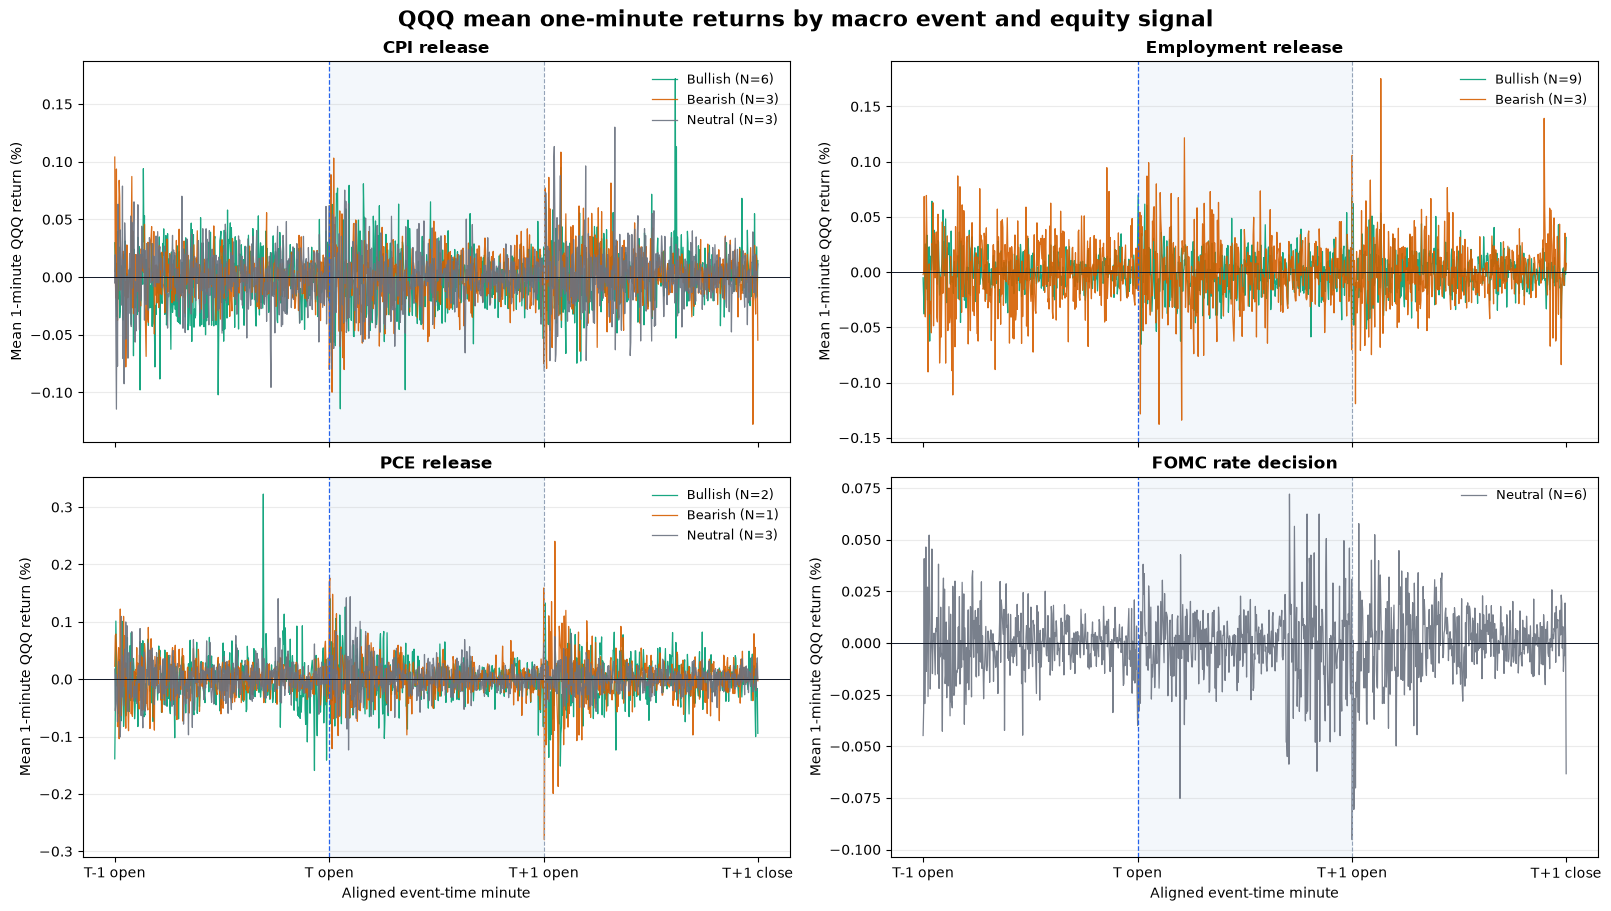

Saved figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_event_type_direction_mean_minute_return.png


In [13]:
import matplotlib.pyplot as plt

EVENT_TITLES = {
    "CPI_RELEASE": "CPI release",
    "EMPLOYMENT_RELEASE": "Employment release",
    "PCE_RELEASE": "PCE release",
    "FOMC_RATE_DECISION": "FOMC rate decision",
}
LABEL_NAMES = {"利好": "Bullish", "利空": "Bearish", "中性": "Neutral"}
LABEL_COLORS = {"利好": "#009E73", "利空": "#D55E00", "中性": "#6B7280"}
event_order = ["CPI_RELEASE", "EMPLOYMENT_RELEASE", "PCE_RELEASE", "FOMC_RATE_DECISION"]

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, constrained_layout=True)
for ax, event_type in zip(axes.flat, event_order):
    event_plot = event_direction_minute_avg.loc[
        event_direction_minute_avg["event_types"].eq(event_type)
    ]
    ax.axvspan(390, 779, color="#EAF2F8", alpha=0.55, zorder=0)
    for equity_label in VALID_EQUITY_LABELS:
        group_plot = event_plot.loc[event_plot["equity_label"].eq(equity_label)].sort_values("aligned_minute")
        if group_plot.empty:
            continue
        n_events = int(group_plot["event_count"].max())
        ax.plot(
            group_plot["aligned_minute"],
            group_plot["mean_minute_return_pct"],
            color=LABEL_COLORS[equity_label],
            linewidth=0.9,
            alpha=0.9,
            label=f"{LABEL_NAMES[equity_label]} (N={n_events})",
        )
    ax.axhline(0, color="#111827", linewidth=0.7)
    ax.axvline(390, color="#2563EB", linestyle="--", linewidth=0.9)
    ax.axvline(780, color="#94A3B8", linestyle="--", linewidth=0.8)
    ax.set_title(EVENT_TITLES[event_type], fontsize=12, fontweight="bold")
    ax.set_ylabel("Mean 1-minute QQQ return (%)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, fontsize=9, loc="upper right")

for ax in axes[-1, :]:
    ax.set_xticks([0, 390, 780, 1169])
    ax.set_xticklabels(["T-1 open", "T open", "T+1 open", "T+1 close"])
    ax.set_xlabel("Aligned event-time minute")
fig.suptitle("QQQ mean one-minute returns by macro event and equity signal", fontsize=16, fontweight="bold")
FIGURE_PATH = DATA_DIR / "QQQ_event_type_direction_mean_minute_return.png"
fig.savefig(FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()
print(f"Saved figure to: {FIGURE_PATH}")

## Regular-session cumulative path (legacy descriptive view)

For each individual event, cumulative QQQ return is measured relative to the closing price on `T-1`. The value is therefore exactly zero at the `T-1` close; the jump to the event-day open includes the overnight return, and the `T+1` path includes the following overnight return. The plotted line is the cross-event mean cumulative return for each `event_types × equity_label` group. Shaded regions show pointwise 95% normal-approximation confidence intervals when the group contains at least two events.

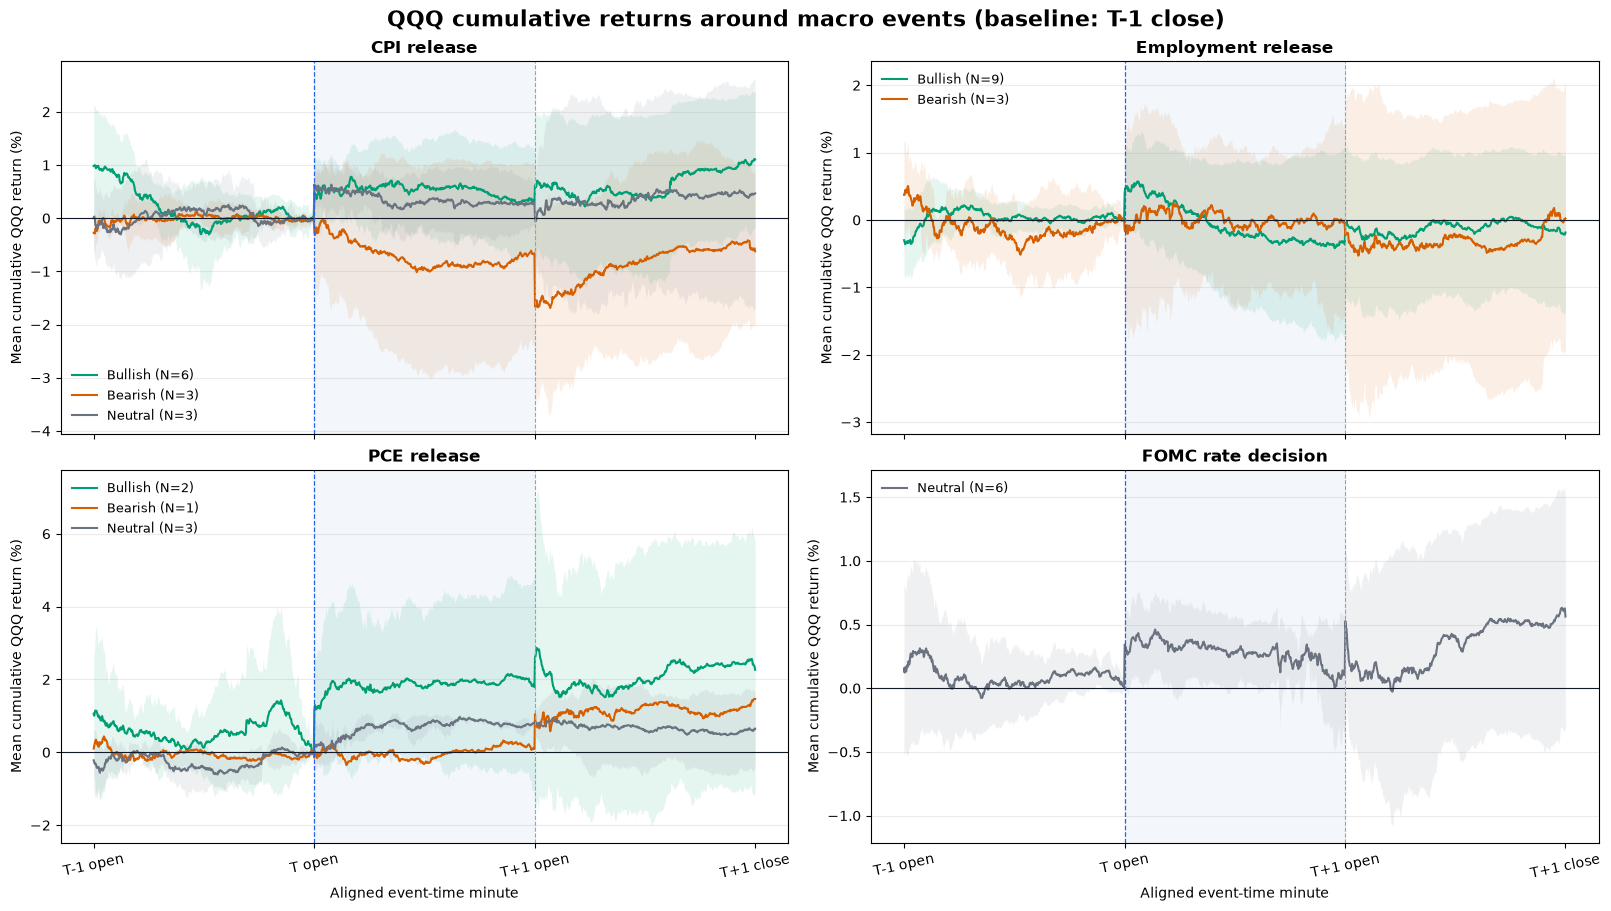

Saved cumulative-return figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_event_type_direction_mean_cumulative_return.png


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, constrained_layout=True)
for ax, event_type in zip(axes.flat, event_order):
    event_plot = event_direction_minute_avg.loc[
        event_direction_minute_avg["event_types"].eq(event_type)
    ]
    ax.axvspan(390, 779, color="#EAF2F8", alpha=0.55, zorder=0)
    for equity_label in VALID_EQUITY_LABELS:
        group_plot = event_plot.loc[event_plot["equity_label"].eq(equity_label)].sort_values("aligned_minute")
        if group_plot.empty:
            continue
        n_events = int(group_plot["event_count"].max())
        x = group_plot["aligned_minute"].to_numpy()
        y = group_plot["mean_cumulative_return_pct"].to_numpy()
        ax.plot(
            x, y,
            color=LABEL_COLORS[equity_label],
            linewidth=1.5,
            label=f"{LABEL_NAMES[equity_label]} (N={n_events})",
        )
        if n_events >= 2:
            ax.fill_between(
                x,
                group_plot["cumulative_ci95_lower"].to_numpy(),
                group_plot["cumulative_ci95_upper"].to_numpy(),
                color=LABEL_COLORS[equity_label],
                alpha=0.10,
                linewidth=0,
            )
    ax.axhline(0, color="#111827", linewidth=0.8)
    ax.axvline(390, color="#2563EB", linestyle="--", linewidth=0.9)
    ax.axvline(780, color="#94A3B8", linestyle="--", linewidth=0.8)
    ax.set_title(EVENT_TITLES[event_type], fontsize=12, fontweight="bold")
    ax.set_ylabel("Mean cumulative QQQ return (%)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, fontsize=9, loc="best")

for ax in axes[-1, :]:
    ax.set_xticks([0, 390, 780, 1169])
    ax.set_xticklabels(["T-1 open", "T open", "T+1 open", "T+1 close"], rotation=12)
    ax.set_xlabel("Aligned event-time minute")
fig.suptitle("QQQ cumulative returns around macro events (baseline: T-1 close)", fontsize=16, fontweight="bold")
CUMULATIVE_FIGURE_PATH = DATA_DIR / "QQQ_event_type_direction_mean_cumulative_return.png"
fig.savefig(CUMULATIVE_FIGURE_PATH, dpi=220, bbox_inches="tight")
plt.show()
print(f"Saved cumulative-return figure to: {CUMULATIVE_FIGURE_PATH}")

# Corrected extended-hours event study centered on each news timestamp

This is the primary event-study dataset and supersedes the regular-session descriptive figures above. The FMP request uses `extended=true`; each normal event contains all returned QQQ one-minute bars from 04:00 through 19:59 ET on `T-1`, the event date `T`, and `T+1`.

Every event uses its own `earliest_news_datetime_et`. The containing minute is mapped to `relative_event_minute = 0`, so an 08:31 release and an 08:33 release are both centered at zero. Cumulative return is measured relative to the last fully completed one-minute bar before the news minute. The exact timestamp, including seconds, remains in the audit table.

The 2026-04-03 release occurred on Good Friday while QQQ was closed. Its adjacent trading sessions are retained, but it contributes no observation at `t=0`; no price is fabricated.

In [15]:
EXTENDED_INTRADAY_PATH = DATA_DIR / "QQQ_event_intraday_1min_extended.csv"
EXTENDED_SUMMARY_PATH = DATA_DIR / "QQQ_event_intraday_summary_extended.csv"

if not EXTENDED_INTRADAY_PATH.exists():
    subprocess.run(
        [
            sys.executable,
            str(ROOT / "scripts" / "download_event_intraday_fmp.py"),
            "--symbol", "QQQ", "--extended",
        ],
        check=True,
    )

extended_minute_returns_df = pd.read_csv(EXTENDED_INTRADAY_PATH)
extended_event_summary_df = pd.read_csv(EXTENDED_SUMMARY_PATH)
extended_minute_returns_df["release_date"] = pd.to_datetime(extended_minute_returns_df["release_date"])
extended_minute_returns_df["trading_date"] = pd.to_datetime(extended_minute_returns_df["trading_date"])
for column in [
    "datetime_et", "official_release_datetime_et", "earliest_news_datetime_et",
    "news_minute_et", "pre_news_reference_datetime_et",
]:
    extended_minute_returns_df[column] = (
        pd.to_datetime(extended_minute_returns_df[column], utc=True, errors="coerce")
        .dt.tz_convert("America/New_York")
    )
extended_minute_returns_df["relative_event_minute"] = pd.to_numeric(
    extended_minute_returns_df["relative_event_minute"], errors="coerce"
).astype("Int64")

EVENT_TIME_AUDIT_PATH = DATA_DIR / "QQQ_extended_event_news_time_audit.csv"
event_time_audit_df = extended_event_summary_df[[
    "release_date", "event_ids", "event_types", "equity_label",
    "earliest_news_datetime_et", "news_minute_et", "event_is_trading_day",
    "news_minute_available", "t_minus_1_date", "event_trading_date",
    "t_plus_1_date", "minute_rows", "status",
]].copy()
event_time_audit_df.to_csv(EVENT_TIME_AUDIT_PATH, index=False, encoding="utf-8-sig")

print(f"Loaded {len(extended_minute_returns_df):,} extended-hours minute bars.")
print("Clock-time coverage:", extended_minute_returns_df["datetime_et"].dt.strftime("%H:%M").min(), "to", extended_minute_returns_df["datetime_et"].dt.strftime("%H:%M").max(), "ET")
print("Events with a tradable news minute:", int(event_time_audit_df["news_minute_available"].sum()), "of", len(event_time_audit_df))
display(event_time_audit_df)

Loaded 102,536 extended-hours minute bars.


Clock-time coverage: 04:00 to 19:59 ET
Events with a tradable news minute: 35 of 36


,release_date,event_ids,event_types,equity_label,earliest_news_datetime_et,news_minute_et,event_is_trading_day,news_minute_available,t_minus_1_date,event_trading_date,t_plus_1_date,minute_rows,status
0,2025-10-24,CPI_2025-09,CPI_RELEASE,利好,2025-10-24 08:31:04-04:00,2025-10-24 08:31:00-04:00,True,True,2025-10-23,2025-10-24,2025-10-27,2880,ok
1,2025-10-29,FOMC_2025-10-29,FOMC_RATE_DECISION,中性,2025-10-29 14:00:16-04:00,2025-10-29 14:00:00-04:00,True,True,2025-10-28,2025-10-29,2025-10-30,2880,ok
2,2025-11-20,EMPLOYMENT_2025-09,EMPLOYMENT_RELEASE,利好,2025-11-20 08:31:03-05:00,2025-11-20 08:31:00-05:00,True,True,2025-11-19,2025-11-20,2025-11-21,2880,ok
3,2025-12-10,FOMC_2025-12-10,FOMC_RATE_DECISION,中性,2025-12-10 14:00:51-05:00,2025-12-10 14:00:00-05:00,True,True,2025-12-09,2025-12-10,2025-12-11,2867,ok
4,2025-12-16,EMPLOYMENT_2025-11,EMPLOYMENT_RELEASE,利空,2025-12-16 08:32:01-05:00,2025-12-16 08:32:00-05:00,True,True,2025-12-15,2025-12-16,2025-12-17,2872,ok
5,2025-12-18,CPI_2025-11,CPI_RELEASE,利好,2025-12-18 08:31:28-05:00,2025-12-18 08:31:00-05:00,True,True,2025-12-17,2025-12-18,2025-12-19,2871,ok
6,2026-01-09,EMPLOYMENT_2025-12,EMPLOYMENT_RELEASE,利好,2026-01-09 08:31:00-05:00,2026-01-09 08:31:00-05:00,True,True,2026-01-08,2026-01-09,2026-01-12,2873,ok
7,2026-01-13,CPI_2025-12,CPI_RELEASE,利好,2026-01-13 08:34:00-05:00,2026-01-13 08:34:00-05:00,True,True,2026-01-12,2026-01-13,2026-01-14,2870,ok
8,2026-01-22,PCE_2025-10_2025-11,PCE_RELEASE,中性,2026-01-22 10:13:00-05:00,2026-01-22 10:13:00-05:00,True,True,2026-01-21,2026-01-22,2026-01-23,2875,ok
9,2026-01-28,FOMC_2026-01-28,FOMC_RATE_DECISION,中性,2026-01-28 14:00:19-05:00,2026-01-28 14:00:00-05:00,True,True,2026-01-27,2026-01-28,2026-01-29,2871,ok


## Event-time aggregation

The response variable is `return_from_pre_news_price_pct`. For a news timestamp such as 08:31:04, the 08:31 bar is `t=0` and the 08:30 close is the reference price. Group means are calculated separately for each `event_types × equity_label × relative_event_minute`. `event_count` reports the number of events actually contributing at that relative minute, so closed-market and unavailable minutes automatically receive no invented observation.

In [16]:
extended_event_time_avg = (
    extended_minute_returns_df.dropna(
        subset=["relative_event_minute", "return_from_pre_news_price_pct"]
    )
    .groupby(["event_types", "equity_label", "relative_event_minute"], observed=True)
    .agg(
        mean_cumulative_return_pct=("return_from_pre_news_price_pct", "mean"),
        median_cumulative_return_pct=("return_from_pre_news_price_pct", "median"),
        std_cumulative_return_pct=("return_from_pre_news_price_pct", "std"),
        mean_minute_return_pct=("minute_return_pct", "mean"),
        event_count=("release_date", "nunique"),
    )
    .reset_index()
)
extended_event_time_avg["relative_event_hour"] = extended_event_time_avg["relative_event_minute"] / 60
extended_event_time_avg["sem_cumulative_return_pct"] = (
    extended_event_time_avg["std_cumulative_return_pct"]
    / np.sqrt(extended_event_time_avg["event_count"])
)
extended_event_time_avg["ci95_lower"] = (
    extended_event_time_avg["mean_cumulative_return_pct"]
    - 1.96 * extended_event_time_avg["sem_cumulative_return_pct"]
)
extended_event_time_avg["ci95_upper"] = (
    extended_event_time_avg["mean_cumulative_return_pct"]
    + 1.96 * extended_event_time_avg["sem_cumulative_return_pct"]
)
EXTENDED_AGGREGATE_PATH = DATA_DIR / "QQQ_extended_event_time_cumulative_return.csv"
extended_event_time_avg.to_csv(EXTENDED_AGGREGATE_PATH, index=False, encoding="utf-8-sig")

news_minute_group_counts = (
    extended_event_time_avg.loc[extended_event_time_avg["relative_event_minute"].eq(0)]
    .pivot(index="event_types", columns="equity_label", values="event_count")
    .fillna(0).astype(int)
)
display(news_minute_group_counts)
print(f"Saved news-centered aggregation to: {EXTENDED_AGGREGATE_PATH}")

equity_label,中性,利好,利空
event_types,,,
CPI_RELEASE,3,6,3
EMPLOYMENT_RELEASE,0,8,3
FOMC_RATE_DECISION,6,0,0
PCE_RELEASE,3,2,1


Saved news-centered aggregation to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_extended_event_time_cumulative_return.csv


In [17]:
EXT_EVENT_ORDER = ["CPI_RELEASE", "EMPLOYMENT_RELEASE", "PCE_RELEASE", "FOMC_RATE_DECISION"]
EXT_EVENT_TITLES = {
    "CPI_RELEASE": "CPI release",
    "EMPLOYMENT_RELEASE": "Employment release",
    "PCE_RELEASE": "PCE release",
    "FOMC_RATE_DECISION": "FOMC rate decision",
}
EXT_LABEL_NAMES = {"利好": "Bullish", "利空": "Bearish", "中性": "Neutral"}
EXT_LABEL_COLORS = {"利好": "#009E73", "利空": "#D55E00", "中性": "#6B7280"}

def draw_news_centered_panel(ax, event_type, xlim_hours):
    event_plot = extended_event_time_avg.loc[
        extended_event_time_avg["event_types"].eq(event_type)
    ].copy()
    ax.axvspan(0, xlim_hours[1], color="#FEF3C7", alpha=0.25, zorder=0)
    for equity_label in ["利好", "利空", "中性"]:
        group_plot = event_plot.loc[event_plot["equity_label"].eq(equity_label)].sort_values("relative_event_minute")
        group_plot = group_plot.loc[group_plot["relative_event_hour"].between(*xlim_hours)]
        if group_plot.empty:
            continue
        near_zero = group_plot.loc[group_plot["relative_event_minute"].between(-1, 1), "event_count"]
        n_at_news = int(near_zero.max()) if not near_zero.empty else 0
        gap_group = group_plot["relative_event_minute"].diff().fillna(1).ne(1).cumsum()
        label_used = False
        for _, segment in group_plot.groupby(gap_group):
            x = segment["relative_event_hour"].to_numpy()
            y = segment["mean_cumulative_return_pct"].to_numpy()
            ax.plot(
                x, y, color=EXT_LABEL_COLORS[equity_label], linewidth=1.5,
                label=(f"{EXT_LABEL_NAMES[equity_label]} (N at t=0: {n_at_news})" if not label_used else None),
            )
            valid_ci = segment["event_count"].ge(2)
            if valid_ci.any():
                ax.fill_between(
                    x, segment["ci95_lower"].to_numpy(), segment["ci95_upper"].to_numpy(),
                    where=valid_ci.to_numpy(), color=EXT_LABEL_COLORS[equity_label], alpha=0.10, linewidth=0,
                )
            label_used = True
    ax.axvline(0, color="#DC2626", linestyle="--", linewidth=1.4)
    ax.axhline(0, color="#111827", linewidth=0.8)
    ax.set_xlim(*xlim_hours)
    ax.set_title(EXT_EVENT_TITLES[event_type], fontsize=12, fontweight="bold")
    ax.set_ylabel("Mean cumulative QQQ return (%)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, fontsize=8, loc="best")

print("News-centered plotting helper is ready. Individual full-window figures follow.")

News-centered plotting helper is ready. Individual full-window figures follow.


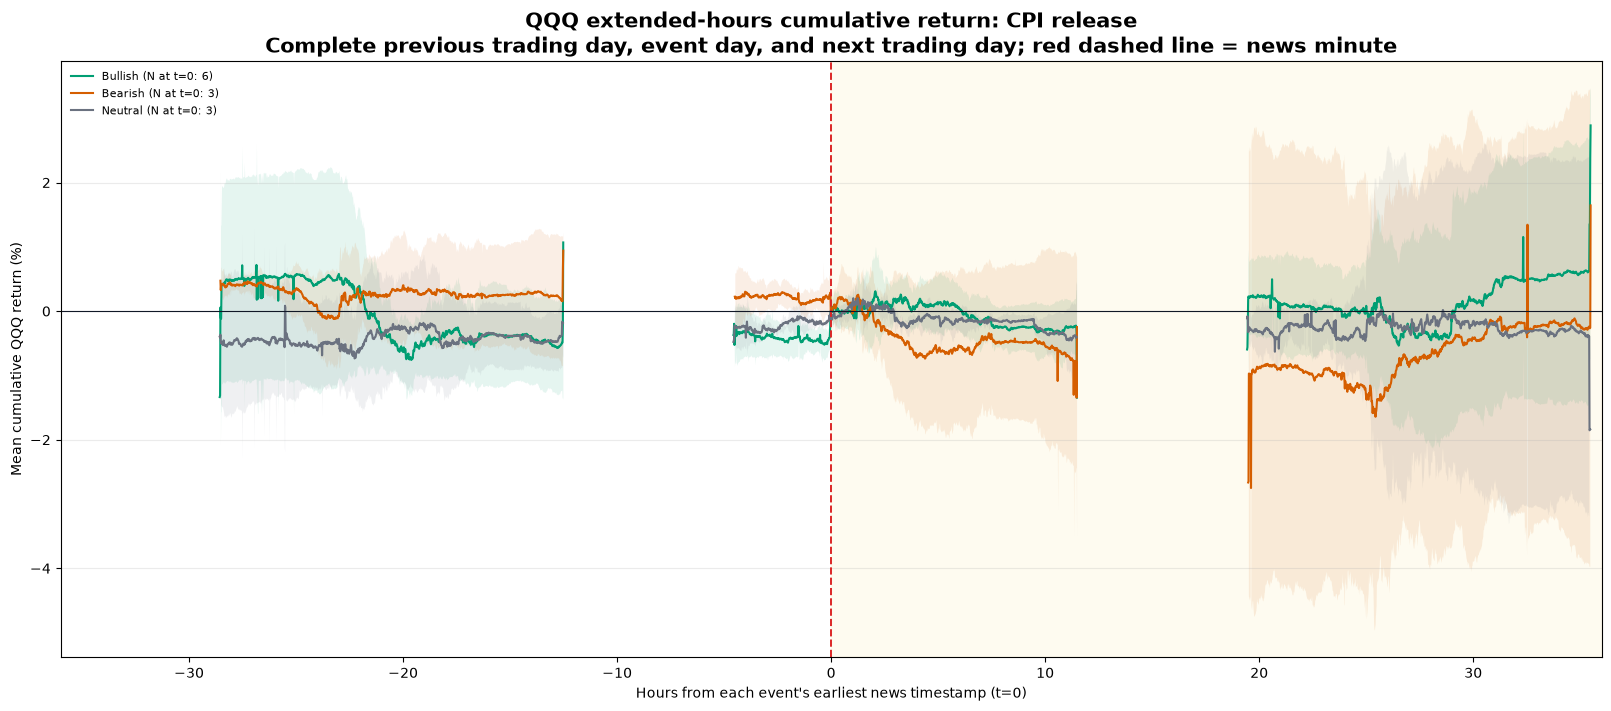

Saved individual full-window figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_extended_CPI_RELEASE_news_centered_full.png


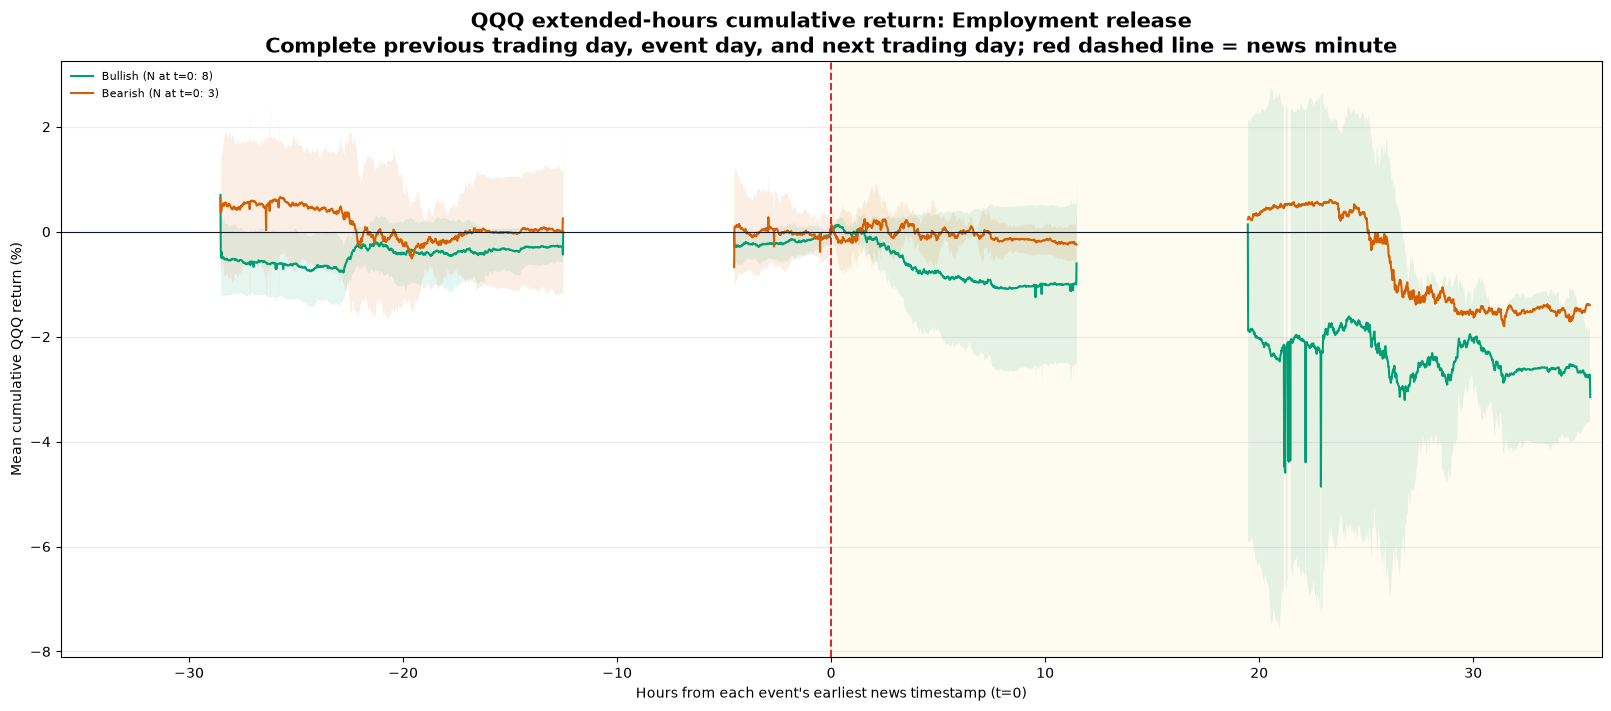

Saved individual full-window figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_extended_EMPLOYMENT_RELEASE_news_centered_full.png


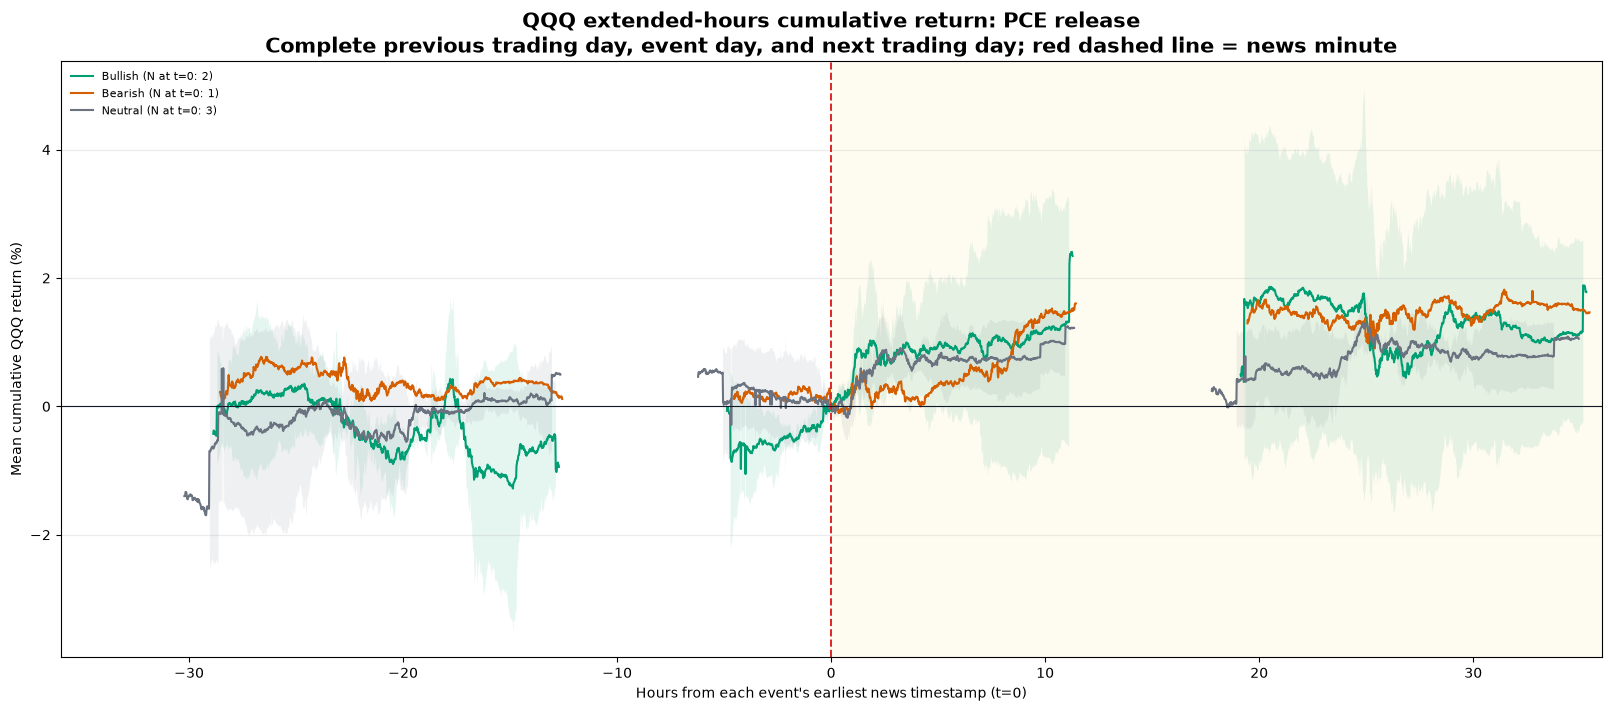

Saved individual full-window figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_extended_PCE_RELEASE_news_centered_full.png


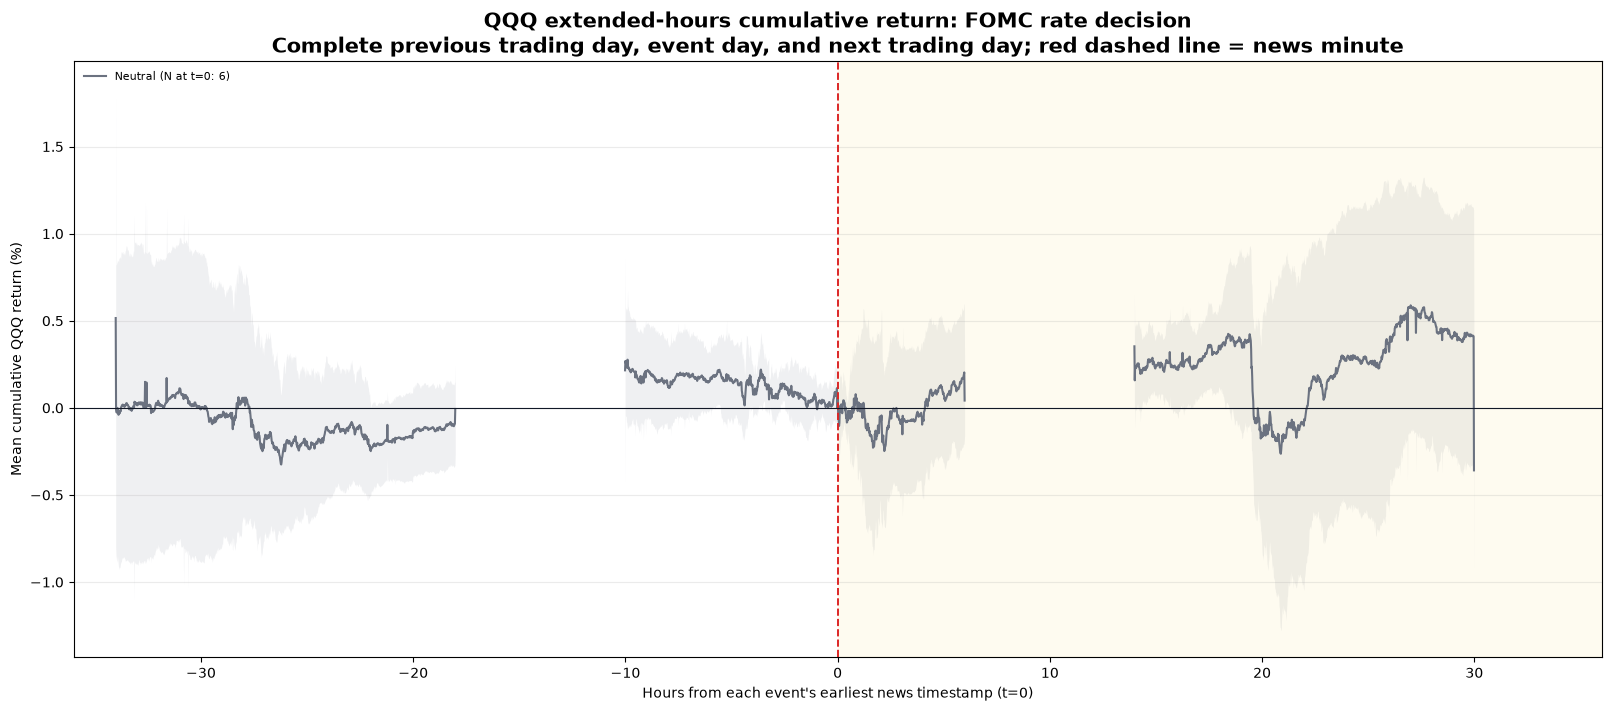

Saved individual full-window figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_extended_FOMC_RATE_DECISION_news_centered_full.png


In [18]:
INDIVIDUAL_FULL_FIGURE_PATHS = {}
for event_type in EXT_EVENT_ORDER:
    fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
    draw_news_centered_panel(ax, event_type, (-36, 36))
    ax.set_xlabel("Hours from each event's earliest news timestamp (t=0)")
    ax.set_title(
        f"QQQ extended-hours cumulative return: {EXT_EVENT_TITLES[event_type]}\n"
        "Complete previous trading day, event day, and next trading day; red dashed line = news minute",
        fontsize=15, fontweight="bold",
    )
    figure_path = DATA_DIR / f"QQQ_extended_{event_type}_news_centered_full.png"
    fig.savefig(figure_path, dpi=220, bbox_inches="tight")
    INDIVIDUAL_FULL_FIGURE_PATHS[event_type] = figure_path
    plt.show()
    print(f"Saved individual full-window figure to: {figure_path}")

# Strongest 50% surprise subsample

Within every `event_types × equity_label` group, events are ranked by `abs(event_surprise_mean)`. The strongest half is retained, with odd group sizes rounded up so that a one-event group is not discarded. The ranking is performed at the event level before minute bars are merged back. `event_surprise_mean` is measured in within-metric sample-standard-deviation units, so the filter compares standardized surprise magnitude rather than raw percentage points or basis points.

All FOMC surprises in the current sample equal zero. Their top-50% selection is therefore a deterministic date-based tie break for plotting only and must not be interpreted as a genuinely stronger FOMC-surprise subsample.

In [19]:
strong_event_universe = (
    extended_minute_returns_df[[
        "event_ids", "event_types", "equity_label",
        "event_surprise_mean", "earliest_news_datetime_et", "release_date"
    ]]
    .drop_duplicates("event_ids")
    .dropna(subset=["event_surprise_mean"])
    .copy()
)
strong_event_universe["abs_event_surprise"] = strong_event_universe["event_surprise_mean"].abs()
group_keys = ["event_types", "equity_label"]
strong_event_universe["group_event_count"] = (
    strong_event_universe.groupby(group_keys, observed=True)["event_ids"].transform("size")
)
strong_event_universe = strong_event_universe.sort_values(
    group_keys + ["abs_event_surprise", "earliest_news_datetime_et", "event_ids"],
    ascending=[True, True, False, True, True],
).reset_index(drop=True)
strong_event_universe["surprise_rank_within_group"] = (
    strong_event_universe.groupby(group_keys, observed=True).cumcount() + 1
)
strong_event_universe["events_to_keep"] = (strong_event_universe["group_event_count"] + 1) // 2
strong_surprise_events = strong_event_universe.loc[
    strong_event_universe["surprise_rank_within_group"] <= strong_event_universe["events_to_keep"]
].copy()

strong_surprise_minute_df = extended_minute_returns_df.merge(
    strong_surprise_events[["event_ids", "abs_event_surprise", "surprise_rank_within_group"]],
    on="event_ids", how="inner", validate="many_to_one",
)
strong_surprise_event_time_avg = (
    strong_surprise_minute_df.dropna(
        subset=["relative_event_minute", "return_from_pre_news_price_pct"]
    )
    .groupby(["event_types", "equity_label", "relative_event_minute"], observed=True)
    .agg(
        mean_cumulative_return_pct=("return_from_pre_news_price_pct", "mean"),
        median_cumulative_return_pct=("return_from_pre_news_price_pct", "median"),
        std_cumulative_return_pct=("return_from_pre_news_price_pct", "std"),
        mean_minute_return_pct=("minute_return_pct", "mean"),
        event_count=("event_ids", "nunique"),
    )
    .reset_index()
)
strong_surprise_event_time_avg["relative_event_hour"] = strong_surprise_event_time_avg["relative_event_minute"] / 60
strong_surprise_event_time_avg["sem_cumulative_return_pct"] = (
    strong_surprise_event_time_avg["std_cumulative_return_pct"]
    / np.sqrt(strong_surprise_event_time_avg["event_count"])
)
strong_surprise_event_time_avg["ci95_lower"] = (
    strong_surprise_event_time_avg["mean_cumulative_return_pct"]
    - 1.96 * strong_surprise_event_time_avg["sem_cumulative_return_pct"]
)
strong_surprise_event_time_avg["ci95_upper"] = (
    strong_surprise_event_time_avg["mean_cumulative_return_pct"]
    + 1.96 * strong_surprise_event_time_avg["sem_cumulative_return_pct"]
)

TOP50_EVENT_PATH = DATA_DIR / "QQQ_top50pct_surprise_selected_events.csv"
TOP50_AGGREGATE_PATH = DATA_DIR / "QQQ_top50pct_surprise_event_time_cumulative_return.csv"
strong_surprise_events.to_csv(TOP50_EVENT_PATH, index=False, encoding="utf-8-sig")
strong_surprise_event_time_avg.to_csv(TOP50_AGGREGATE_PATH, index=False, encoding="utf-8-sig")

top50_selection_summary = (
    strong_event_universe.groupby(group_keys, observed=True)
    .agg(total_events=("event_ids", "size"), events_kept=("events_to_keep", "first"))
    .reset_index()
)
display(top50_selection_summary)
display(strong_surprise_events[[
    "event_types", "equity_label", "event_ids", "earliest_news_datetime_et",
    "event_surprise_mean", "abs_event_surprise", "surprise_rank_within_group"
]])
print(f"Saved selected events to: {TOP50_EVENT_PATH}")
print(f"Saved strongest-50% aggregation to: {TOP50_AGGREGATE_PATH}")

,event_types,equity_label,total_events,events_kept
0,CPI_RELEASE,中性,3,2
1,CPI_RELEASE,利好,6,3
2,CPI_RELEASE,利空,3,2
3,EMPLOYMENT_RELEASE,利好,9,5
4,EMPLOYMENT_RELEASE,利空,3,2
5,FOMC_RATE_DECISION,中性,6,3
6,PCE_RELEASE,中性,3,2
7,PCE_RELEASE,利好,2,1
8,PCE_RELEASE,利空,1,1


,event_types,equity_label,event_ids,earliest_news_datetime_et,event_surprise_mean,abs_event_surprise,surprise_rank_within_group
0,CPI_RELEASE,中性,CPI_2026-02,2026-03-11 08:31:02-04:00,0.000000,0.000000,1
1,CPI_RELEASE,中性,CPI_2026-03,2026-04-10 08:31:30-04:00,0.000000,0.000000,2
3,CPI_RELEASE,利好,CPI_2025-11,2025-12-18 08:31:28-05:00,-2.613870,2.613870,1
4,CPI_RELEASE,利好,CPI_2026-06,2026-07-14 08:32:49-04:00,-1.936492,1.936492,2
5,CPI_RELEASE,利好,CPI_2025-09,2025-10-24 08:31:04-04:00,-1.188774,1.188774,3
9,CPI_RELEASE,利空,CPI_2026-04,2026-05-12 08:30:47-04:00,0.645497,0.645497,1
10,CPI_RELEASE,利空,CPI_2026-09,2026-10-14 08:31:19-04:00,0.581008,0.581008,2
12,EMPLOYMENT_RELEASE,利好,EMPLOYMENT_2026-01,2026-02-11 08:32:15-05:00,-1.088214,1.088214,1
13,EMPLOYMENT_RELEASE,利好,EMPLOYMENT_2025-09,2025-11-20 08:31:03-05:00,0.911475,0.911475,2
14,EMPLOYMENT_RELEASE,利好,EMPLOYMENT_2026-04,2026-05-08 08:31:00-04:00,0.792587,0.792587,3


Saved selected events to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_top50pct_surprise_selected_events.csv
Saved strongest-50% aggregation to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_top50pct_surprise_event_time_cumulative_return.csv


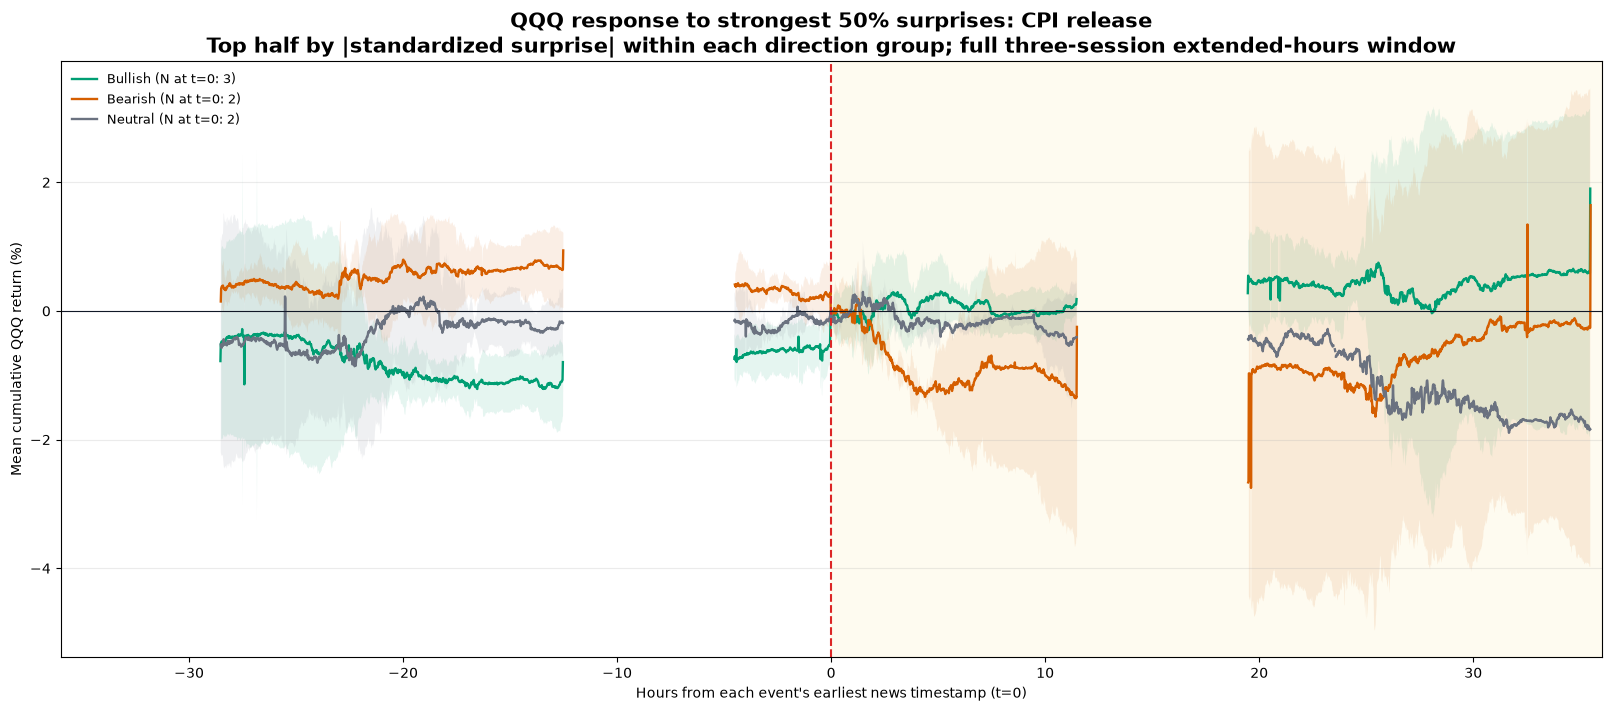

Saved strongest-50% figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_extended_CPI_RELEASE_top50pct_surprise_full.png


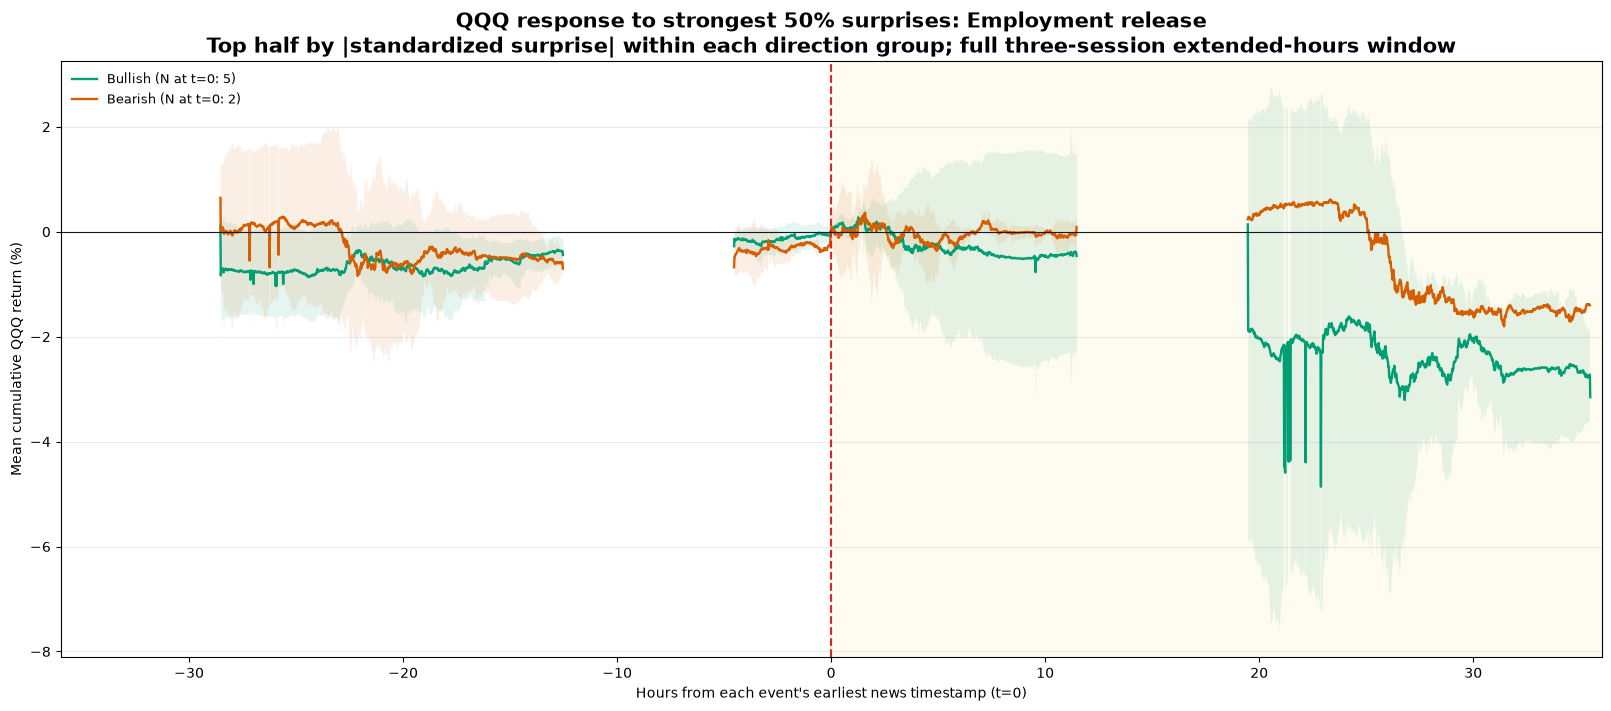

Saved strongest-50% figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_extended_EMPLOYMENT_RELEASE_top50pct_surprise_full.png


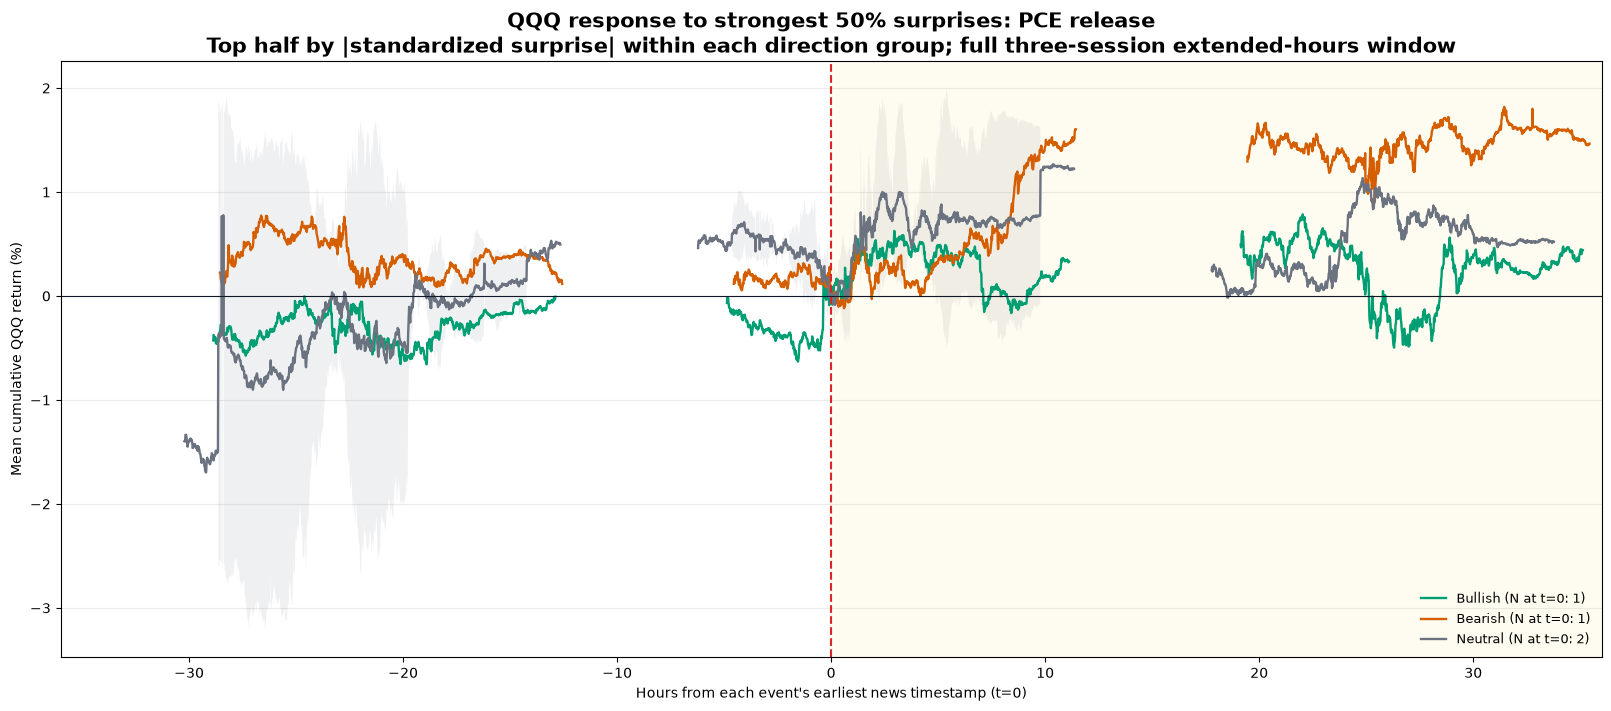

Saved strongest-50% figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_extended_PCE_RELEASE_top50pct_surprise_full.png


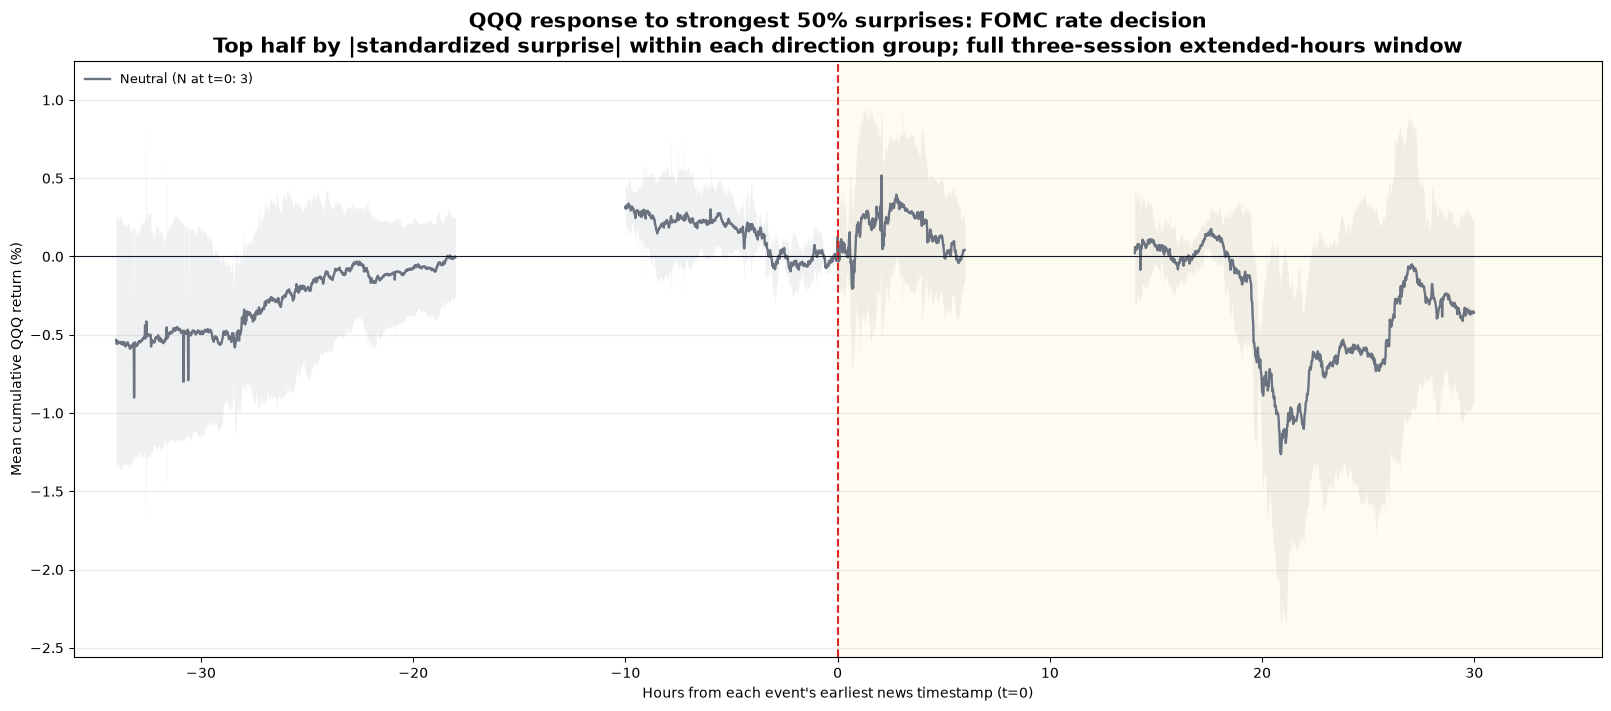

Saved strongest-50% figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification\QQQ_extended_FOMC_RATE_DECISION_top50pct_surprise_full.png


In [20]:
def draw_strong_surprise_panel(ax, event_type, xlim_hours=(-36, 36)):
    event_plot = strong_surprise_event_time_avg.loc[
        strong_surprise_event_time_avg["event_types"].eq(event_type)
    ].copy()
    ax.axvspan(0, xlim_hours[1], color="#FEF3C7", alpha=0.25, zorder=0)
    for equity_label in EXT_LABEL_NAMES:
        group_plot = event_plot.loc[event_plot["equity_label"].eq(equity_label)].sort_values("relative_event_minute")
        group_plot = group_plot.loc[group_plot["relative_event_hour"].between(*xlim_hours)]
        if group_plot.empty:
            continue
        near_zero = group_plot.loc[group_plot["relative_event_minute"].between(-1, 1), "event_count"]
        n_at_news = int(near_zero.max()) if not near_zero.empty else 0
        gap_group = group_plot["relative_event_minute"].diff().fillna(1).ne(1).cumsum()
        label_used = False
        for _, segment in group_plot.groupby(gap_group):
            x = segment["relative_event_hour"].to_numpy()
            y = segment["mean_cumulative_return_pct"].to_numpy()
            ax.plot(
                x, y, color=EXT_LABEL_COLORS[equity_label], linewidth=1.7,
                label=(f"{EXT_LABEL_NAMES[equity_label]} (N at t=0: {n_at_news})" if not label_used else None),
            )
            valid_ci = segment["event_count"].ge(2)
            if valid_ci.any():
                ax.fill_between(
                    x, segment["ci95_lower"].to_numpy(), segment["ci95_upper"].to_numpy(),
                    where=valid_ci.to_numpy(), color=EXT_LABEL_COLORS[equity_label], alpha=0.10, linewidth=0,
                )
            label_used = True
    ax.axvline(0, color="#DC2626", linestyle="--", linewidth=1.5)
    ax.axhline(0, color="#111827", linewidth=0.8)
    ax.set_xlim(*xlim_hours)
    ax.set_ylabel("Mean cumulative QQQ return (%)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, fontsize=9, loc="best")

TOP50_FIGURE_PATHS = {}
for event_type in EXT_EVENT_ORDER:
    fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
    draw_strong_surprise_panel(ax, event_type, (-36, 36))
    ax.set_xlabel("Hours from each event's earliest news timestamp (t=0)")
    ax.set_title(
        f"QQQ response to strongest 50% surprises: {EXT_EVENT_TITLES[event_type]}\n"
        "Top half by |standardized surprise| within each direction group; full three-session extended-hours window",
        fontsize=15, fontweight="bold",
    )
    figure_path = DATA_DIR / f"QQQ_extended_{event_type}_top50pct_surprise_full.png"
    fig.savefig(figure_path, dpi=220, bbox_inches="tight")
    TOP50_FIGURE_PATHS[event_type] = figure_path
    plt.show()
    print(f"Saved strongest-50% figure to: {figure_path}")

# Three-year macro-news event study (2023-10-16 to 2026-10-16)

This section applies the complete pipeline to 129 official CPI, Employment, PCE, and FOMC anchors. Historical FMP General News was repaired with day-level queries before DeepSeek structured classification. Only events with an identified earliest result story and an interpretable broad-equity direction enter the QQQ sample.

The market window contains the complete 04:00–20:00 ET sessions for the previous trading day, event day, and next trading day. Each event is centered on its own earliest news minute. Full-sample and strongest-50% results are shown as four separate large figures.

,event_types,equity_label,events,first_release,last_release
0,CPI_RELEASE,中性,8,2024-05-15,2026-08-12
1,CPI_RELEASE,利好,9,2025-03-12,2026-07-14
2,CPI_RELEASE,利空,9,2024-02-13,2026-10-14
3,EMPLOYMENT_RELEASE,中性,4,2025-05-02,2026-07-02
4,EMPLOYMENT_RELEASE,利好,12,2024-02-02,2026-09-04
5,EMPLOYMENT_RELEASE,利空,10,2024-03-08,2026-10-02
6,FOMC_RATE_DECISION,中性,13,2024-11-07,2026-09-16
7,PCE_RELEASE,中性,7,2024-11-27,2026-05-28
8,PCE_RELEASE,利好,4,2025-09-26,2026-09-30
9,PCE_RELEASE,利空,1,2026-08-26,2026-08-26


Three-year tradable events: 77
Extended-hours minute rows: 214,330


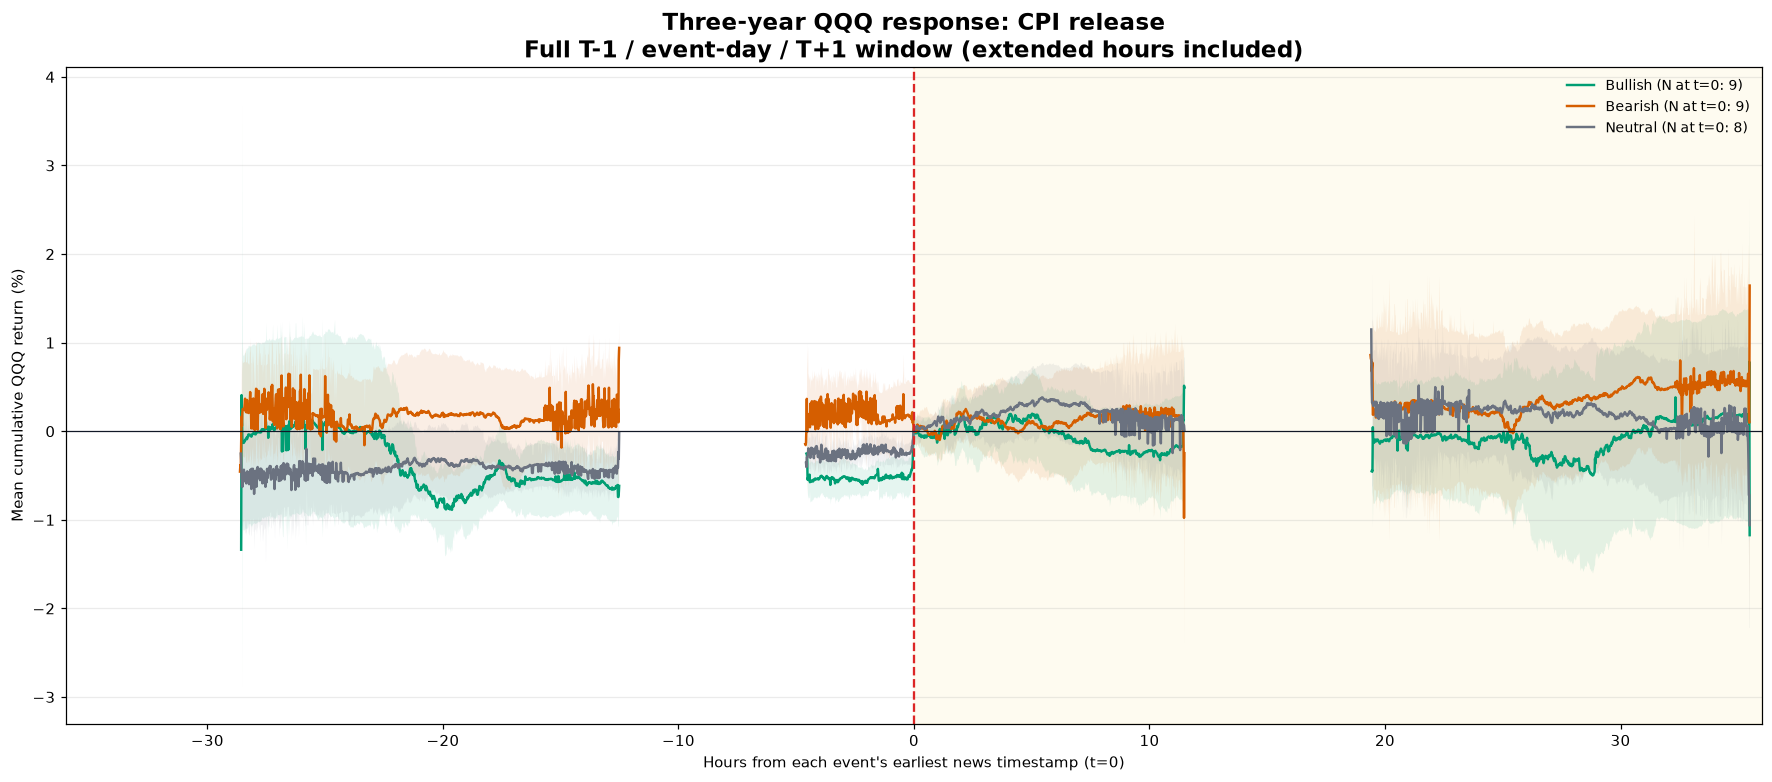

Saved three-year full-sample figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_CPI_RELEASE_news_centered_full.png


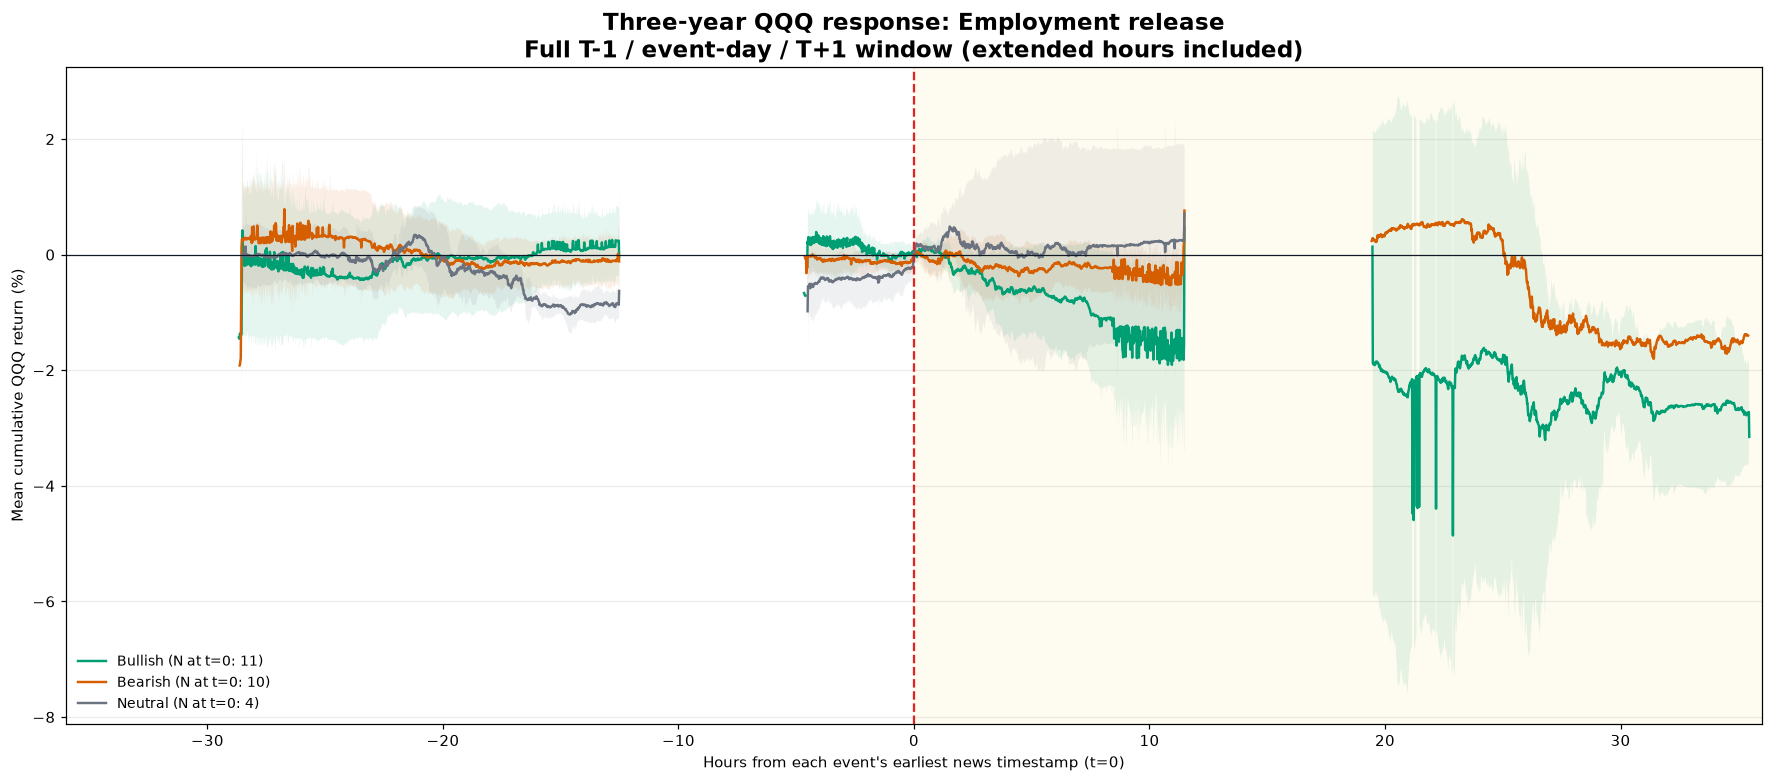

Saved three-year full-sample figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_EMPLOYMENT_RELEASE_news_centered_full.png


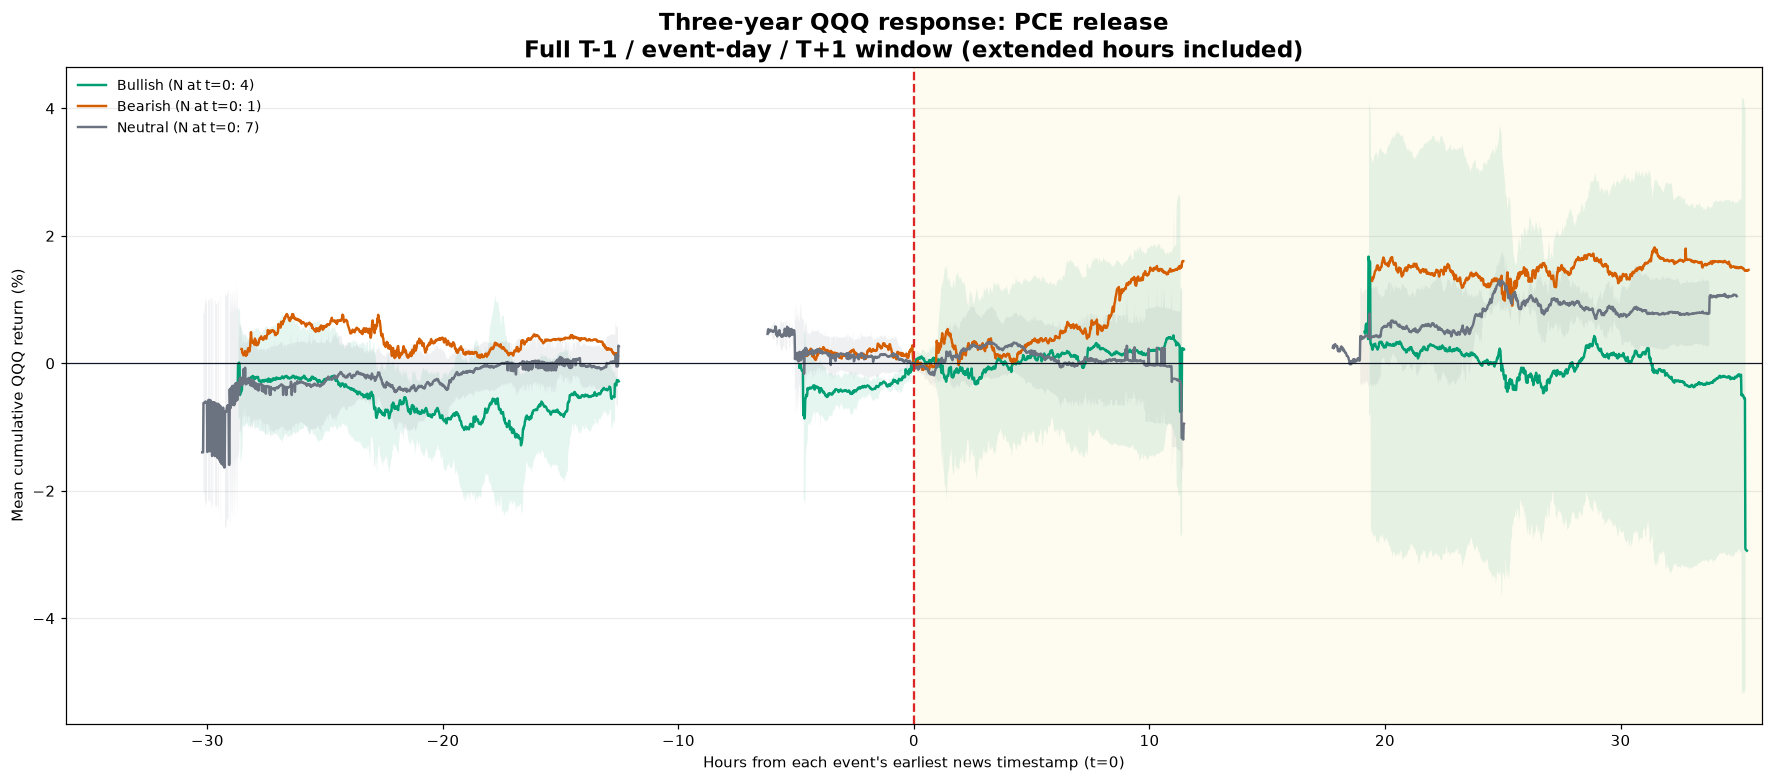

Saved three-year full-sample figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_PCE_RELEASE_news_centered_full.png


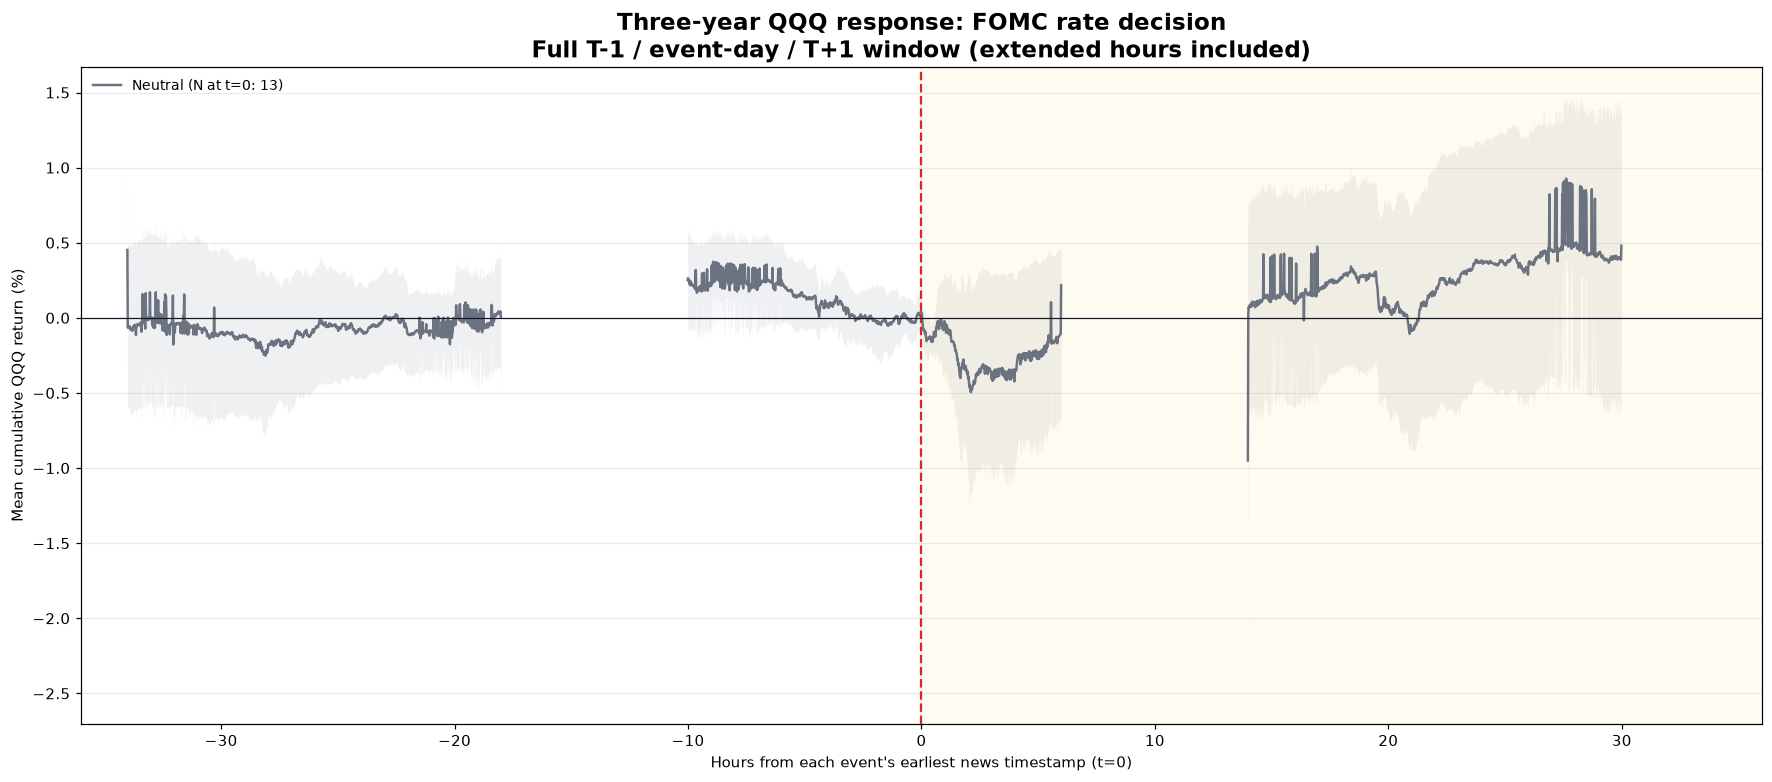

Saved three-year full-sample figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_FOMC_RATE_DECISION_news_centered_full.png


,event_types,equity_label,total_events,events_kept
0,CPI_RELEASE,中性,8,4
1,CPI_RELEASE,利好,9,5
2,CPI_RELEASE,利空,9,5
3,EMPLOYMENT_RELEASE,中性,4,2
4,EMPLOYMENT_RELEASE,利好,12,6
5,EMPLOYMENT_RELEASE,利空,10,5
6,FOMC_RATE_DECISION,中性,13,7
7,PCE_RELEASE,中性,7,4
8,PCE_RELEASE,利好,4,2
9,PCE_RELEASE,利空,1,1


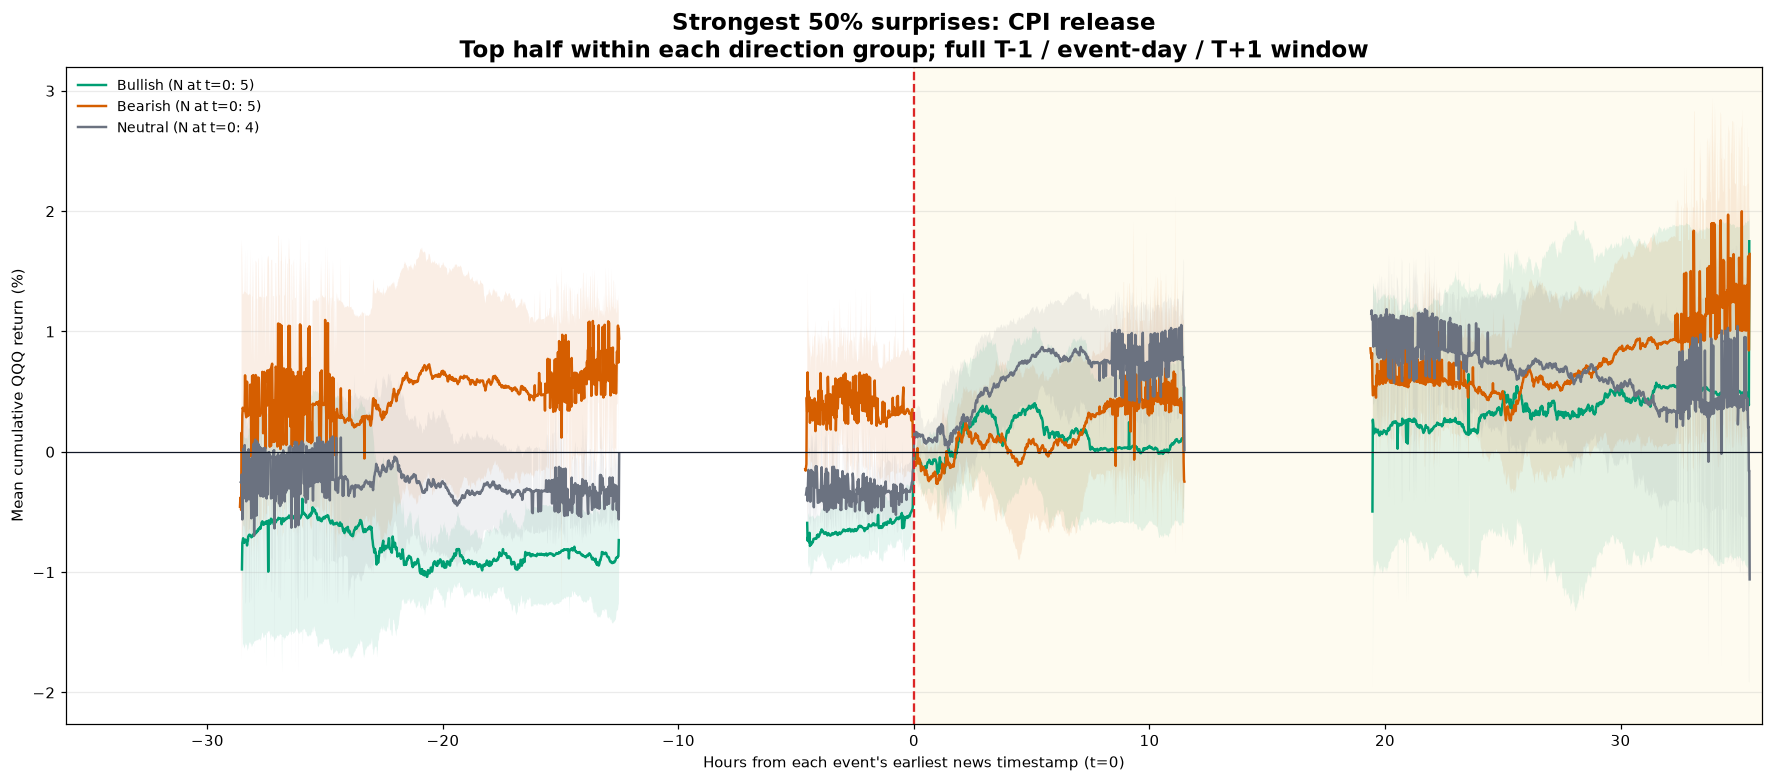

Saved three-year strongest-50% figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_CPI_RELEASE_top50pct_surprise_full.png


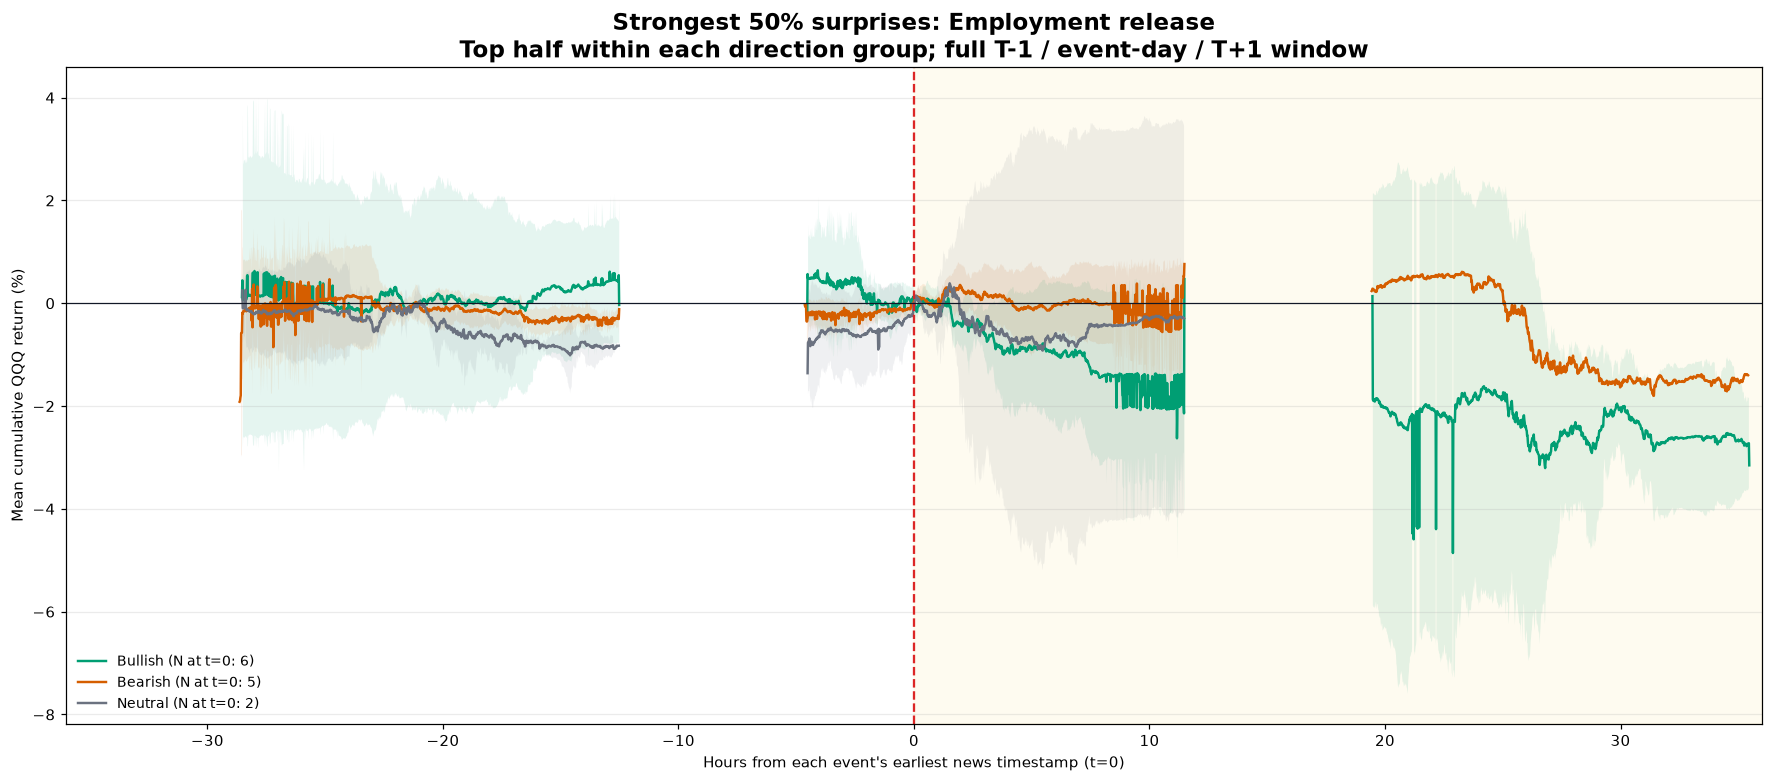

Saved three-year strongest-50% figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_EMPLOYMENT_RELEASE_top50pct_surprise_full.png


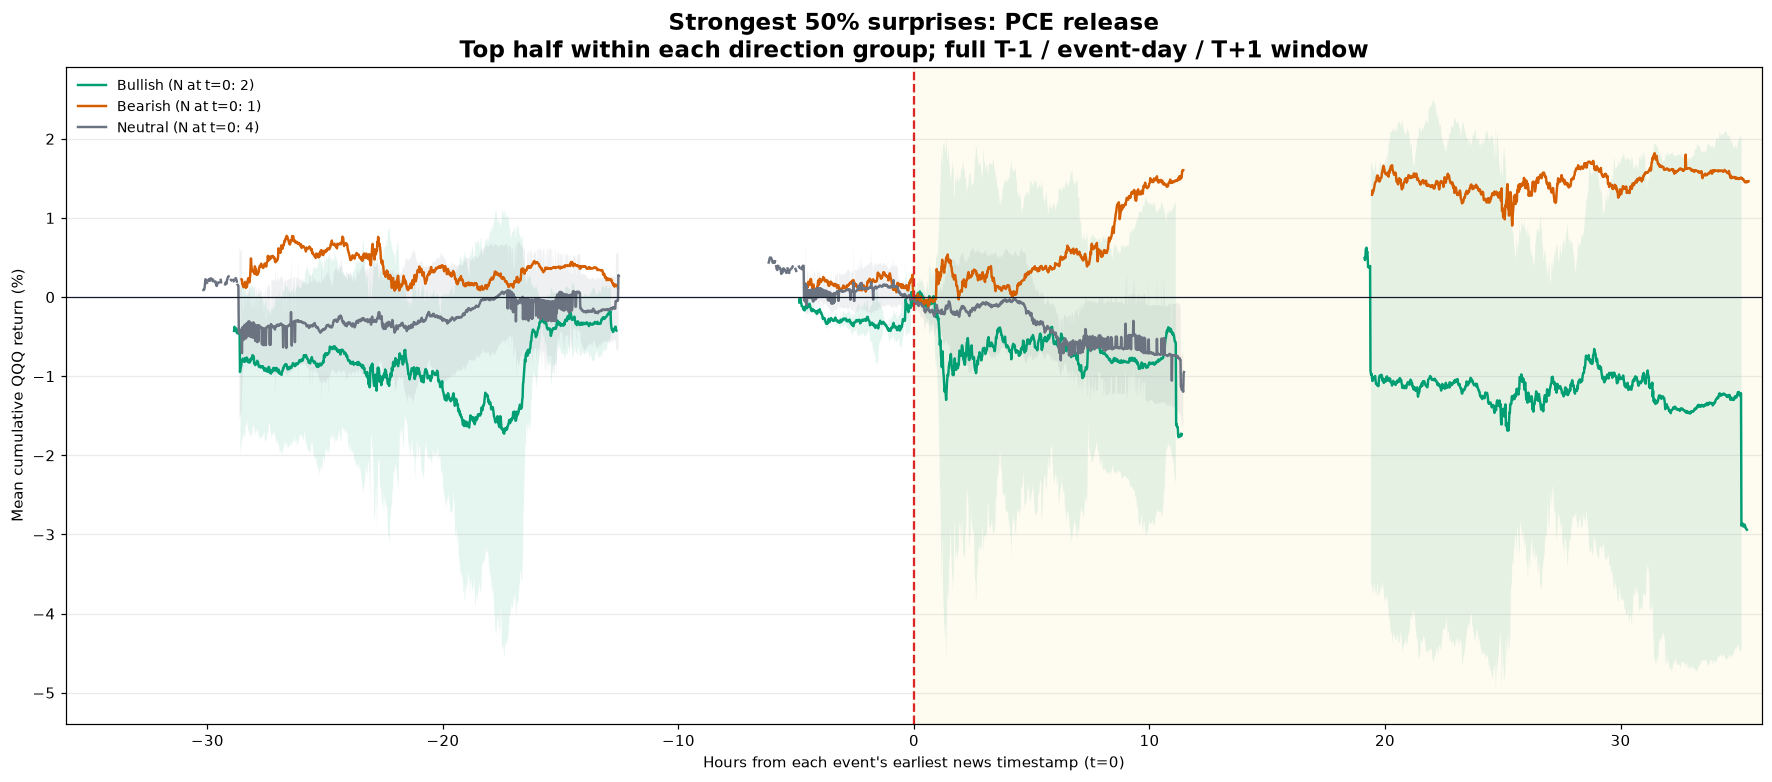

Saved three-year strongest-50% figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_PCE_RELEASE_top50pct_surprise_full.png


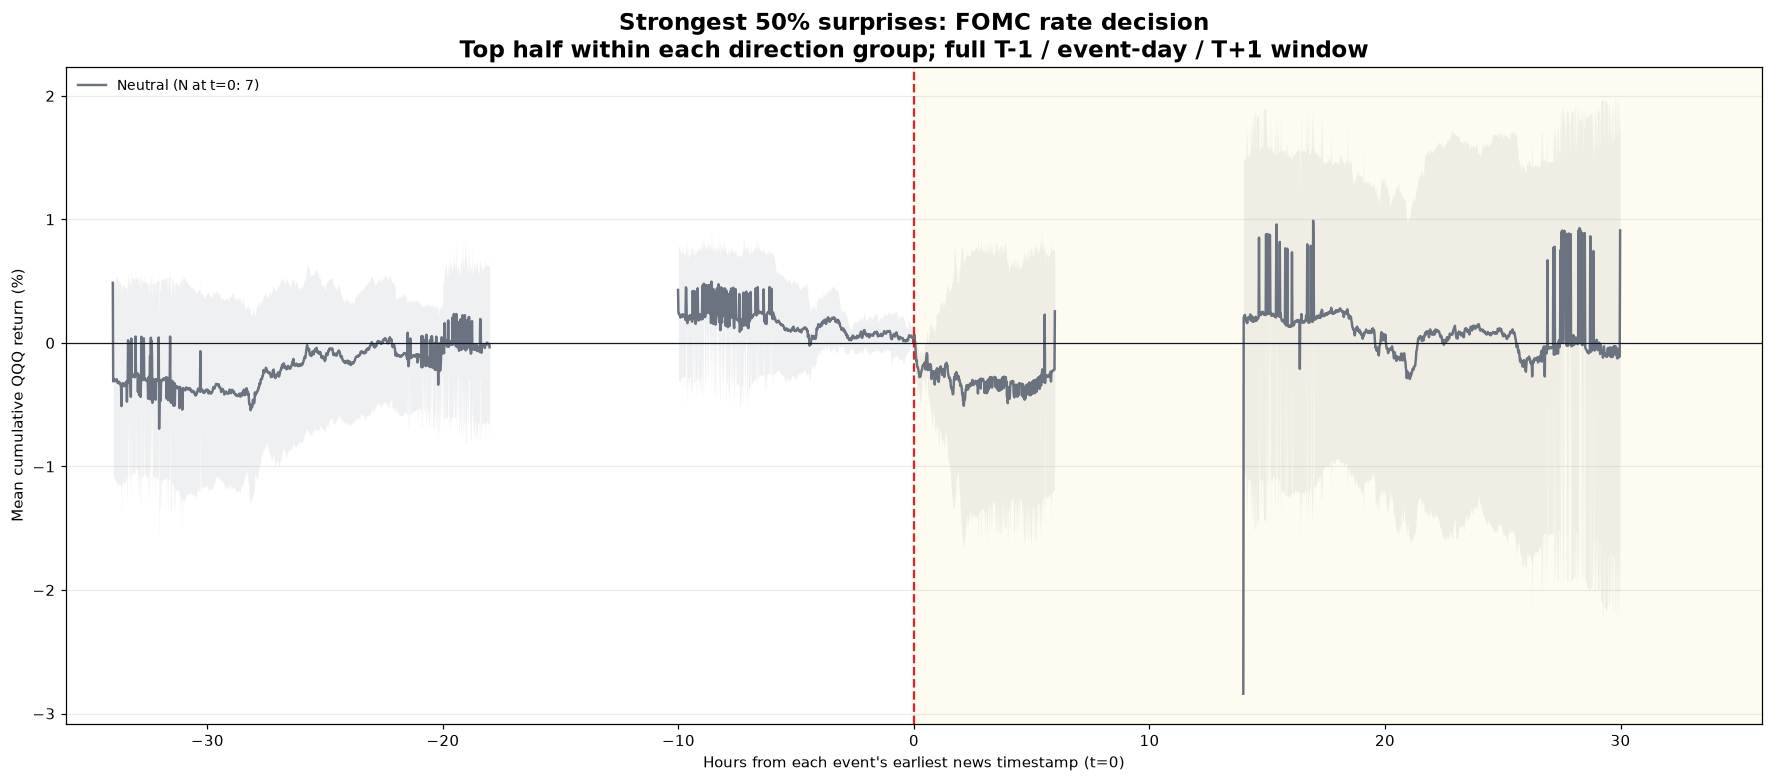

Saved three-year strongest-50% figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_FOMC_RATE_DECISION_top50pct_surprise_full.png


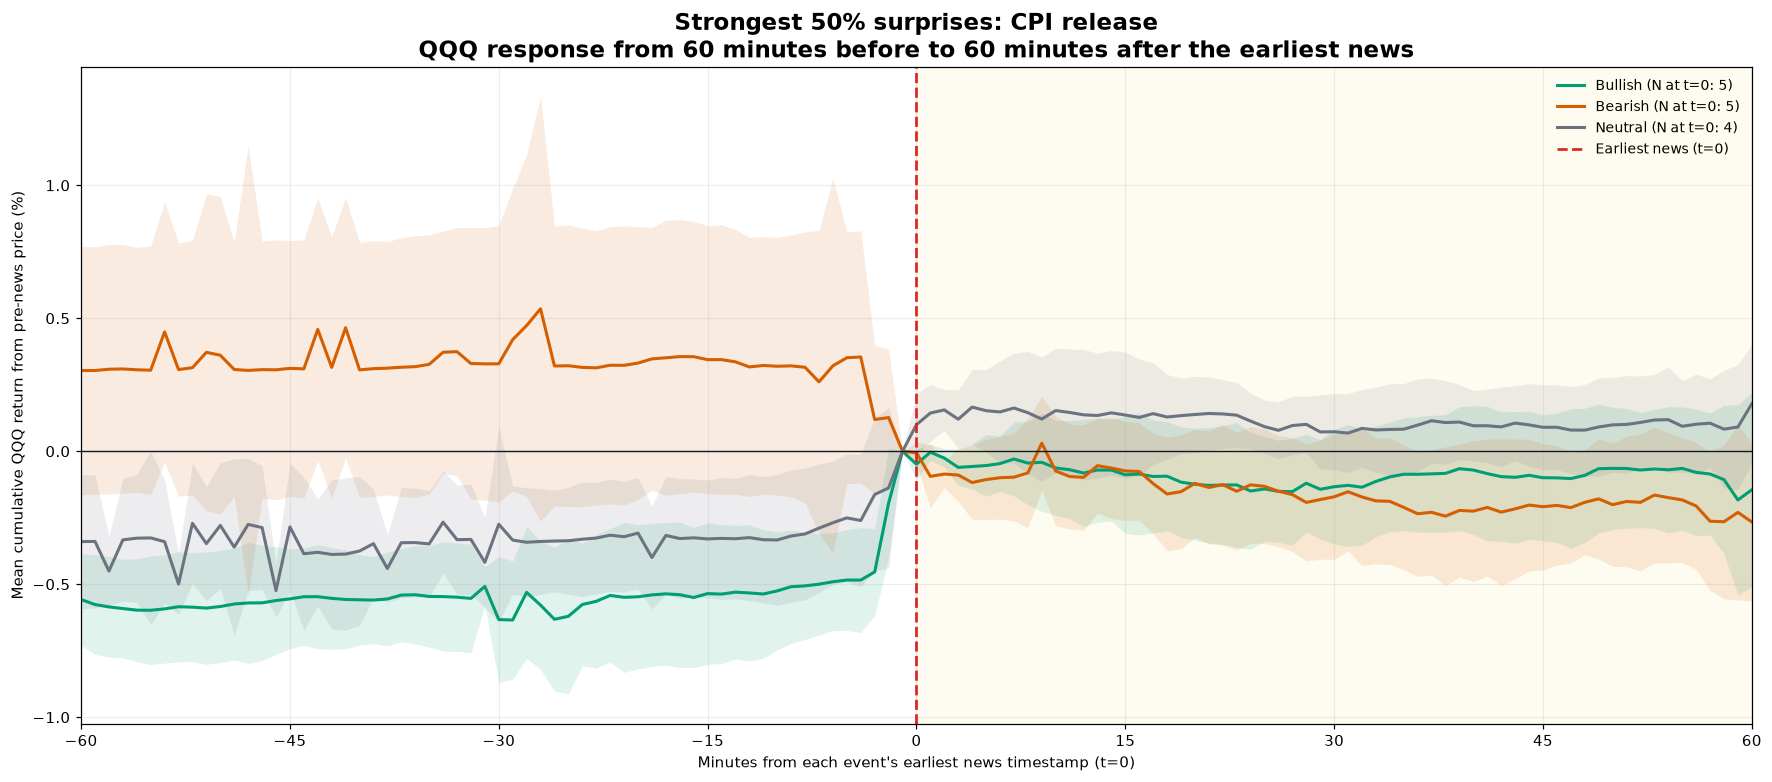

Saved strongest-50% +/-60-minute figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_CPI_RELEASE_top50pct_surprise_pm60min.png


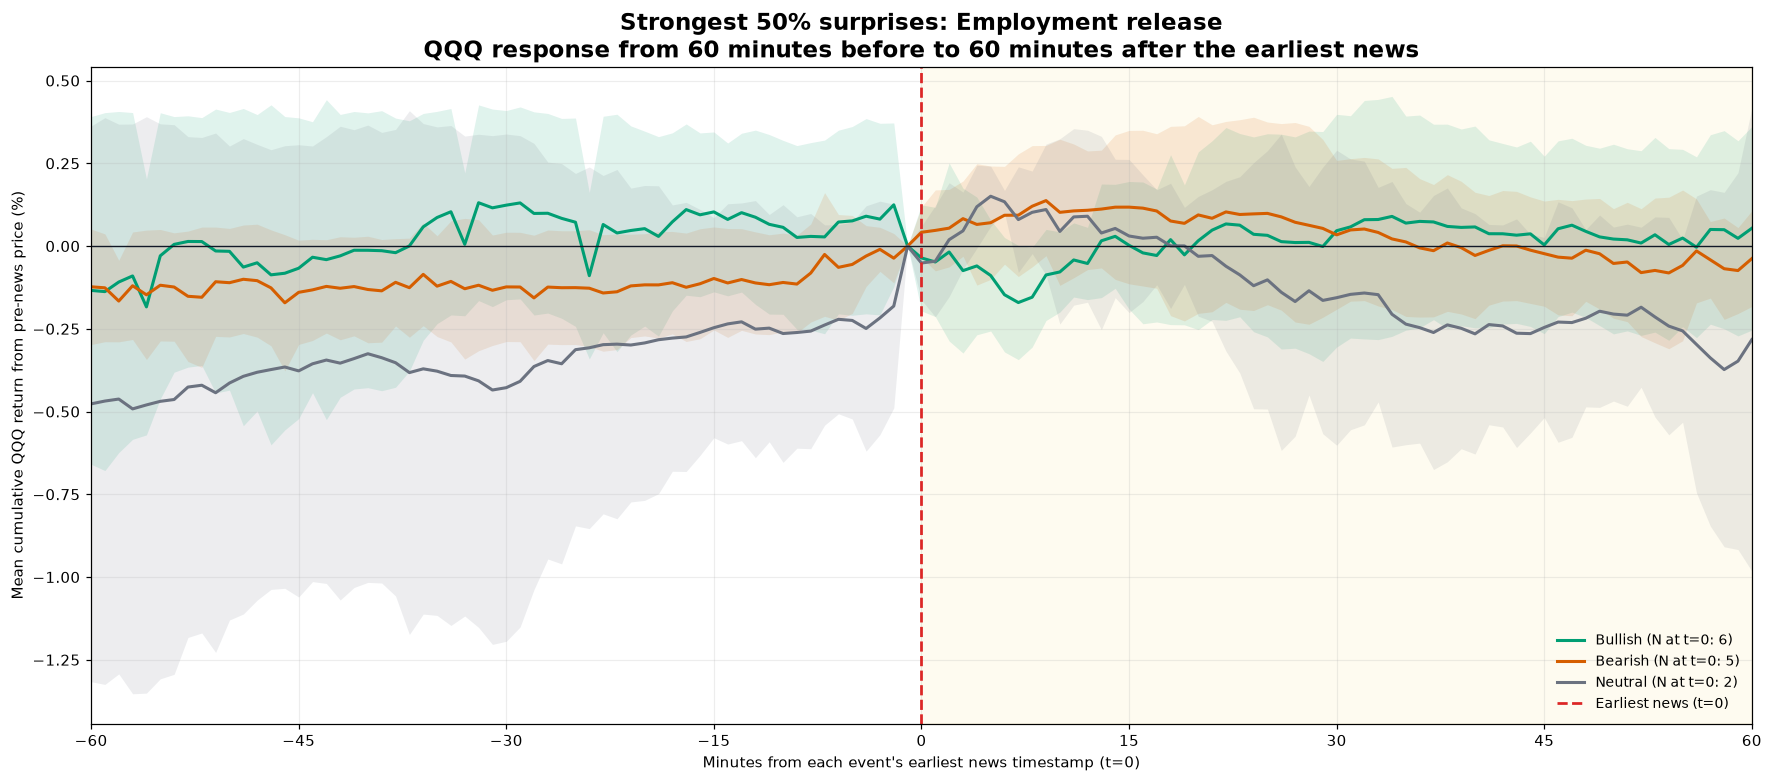

Saved strongest-50% +/-60-minute figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_EMPLOYMENT_RELEASE_top50pct_surprise_pm60min.png


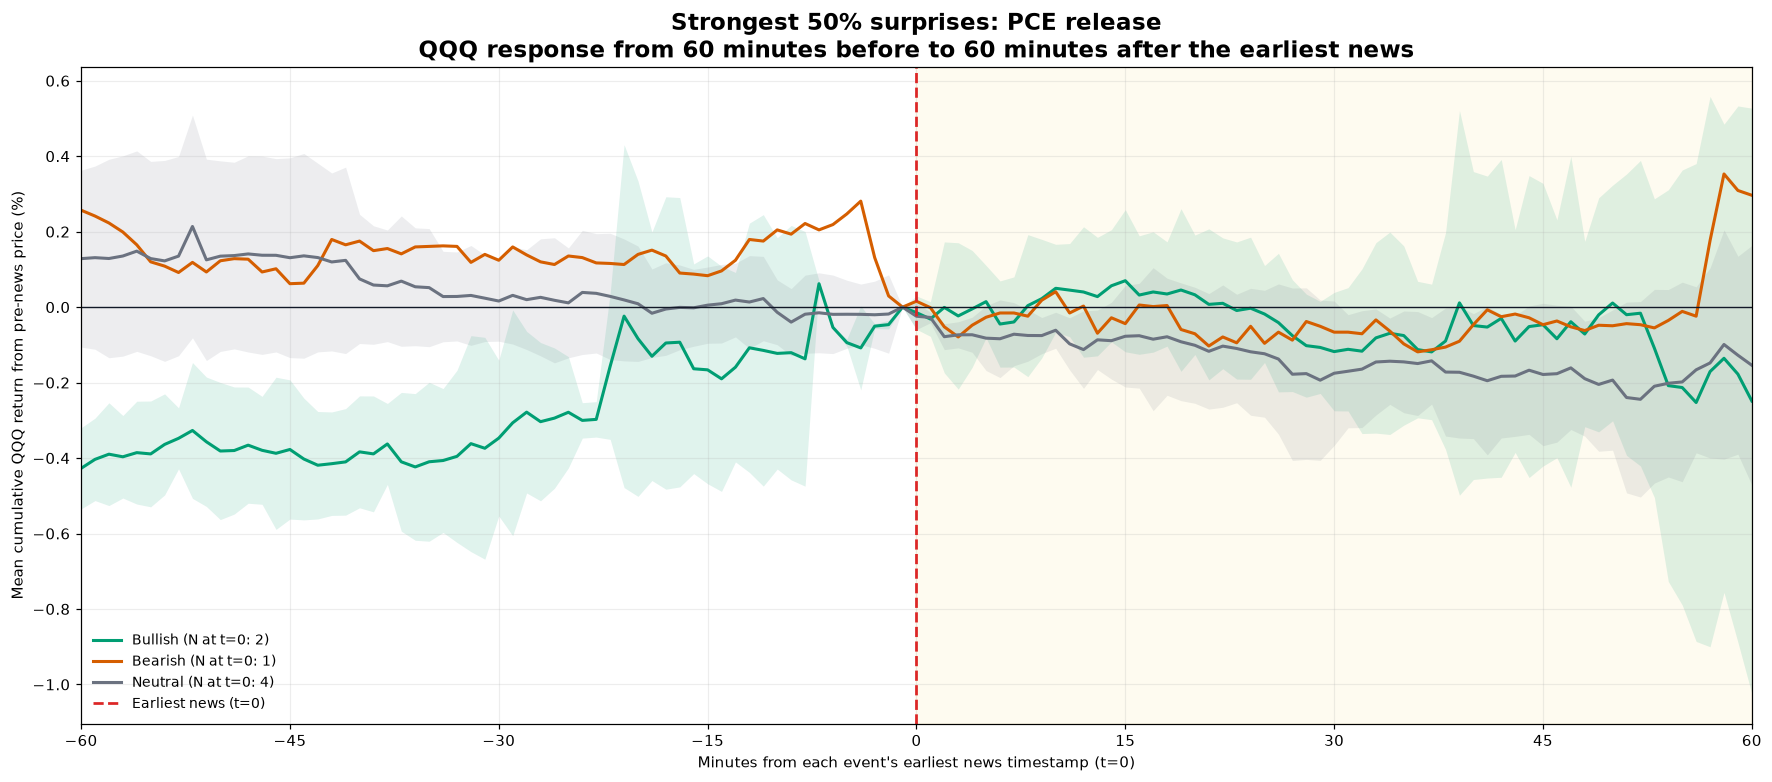

Saved strongest-50% +/-60-minute figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_PCE_RELEASE_top50pct_surprise_pm60min.png


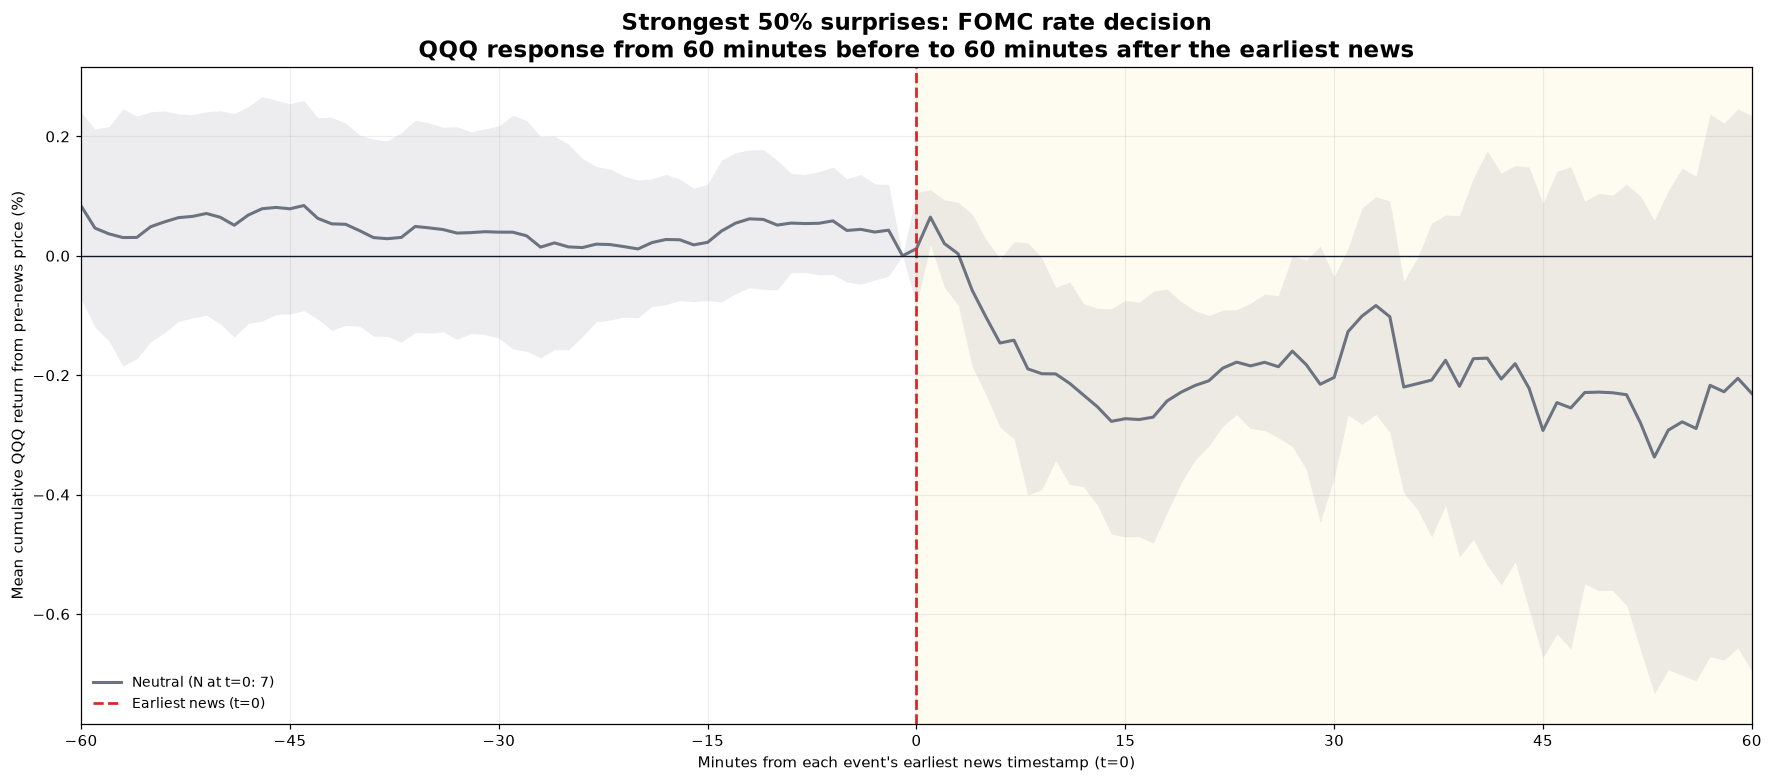

Saved strongest-50% +/-60-minute figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_FOMC_RATE_DECISION_top50pct_surprise_pm60min.png


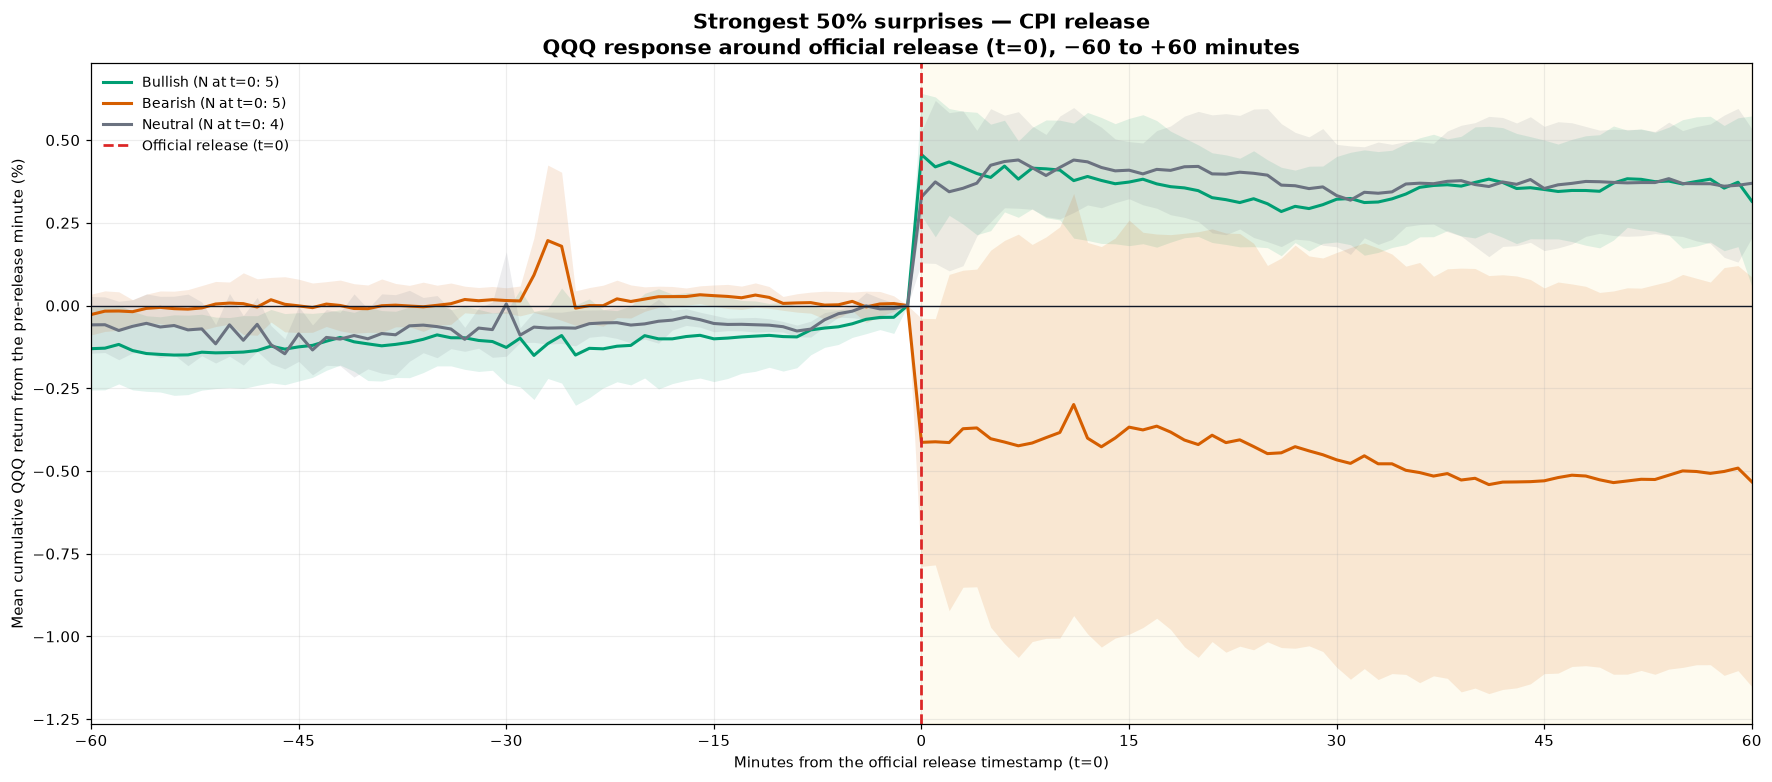

Saved official-centered strongest-50% +/-60-minute figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_CPI_RELEASE_top50pct_surprise_official_pm60min.png


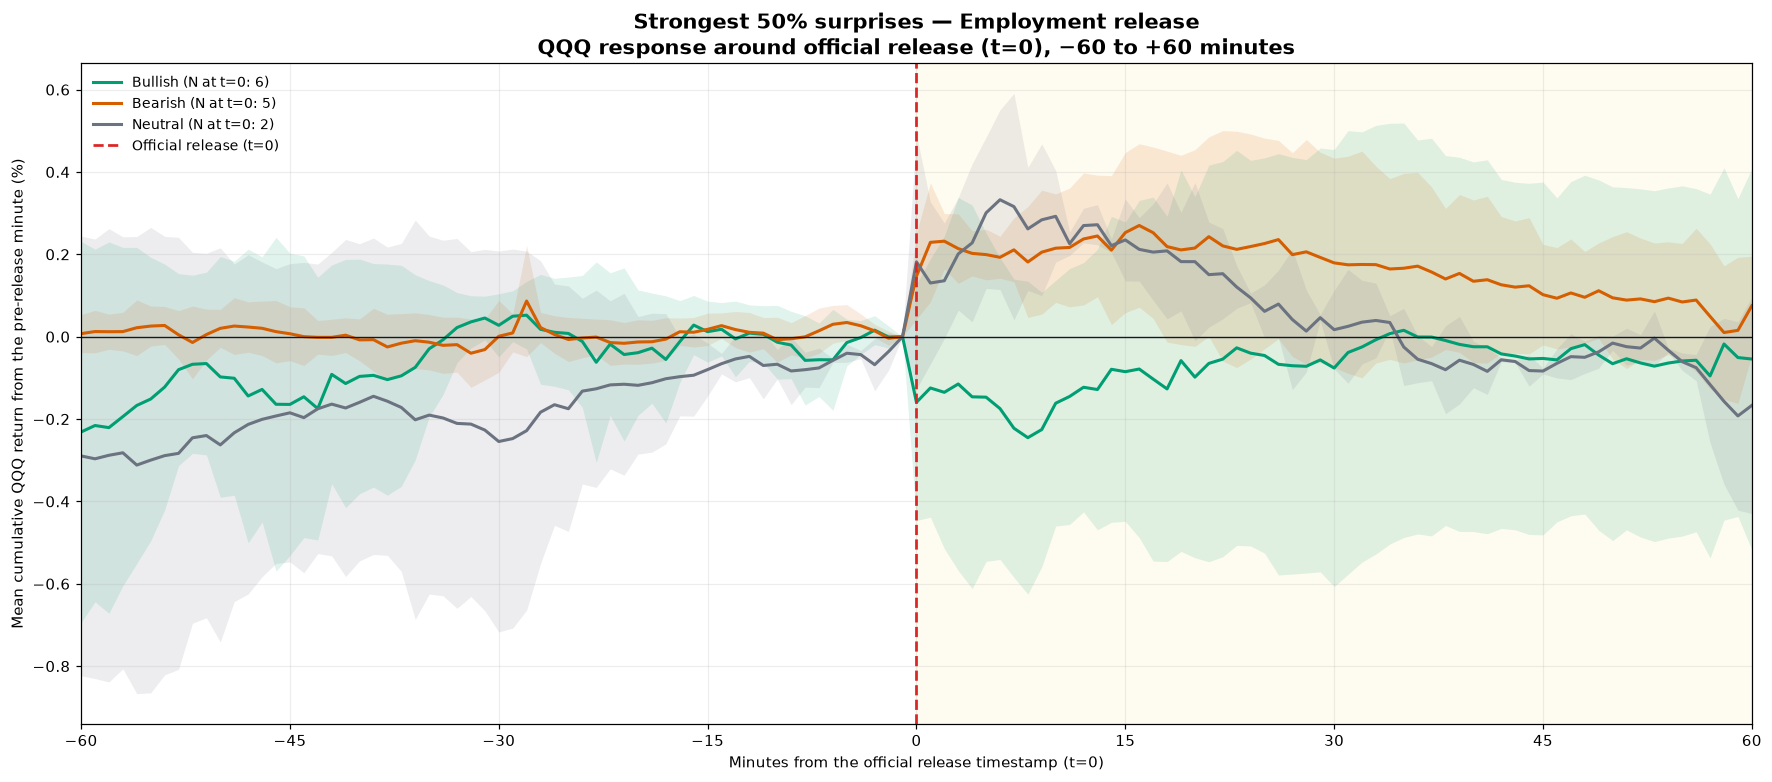

Saved official-centered strongest-50% +/-60-minute figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_EMPLOYMENT_RELEASE_top50pct_surprise_official_pm60min.png


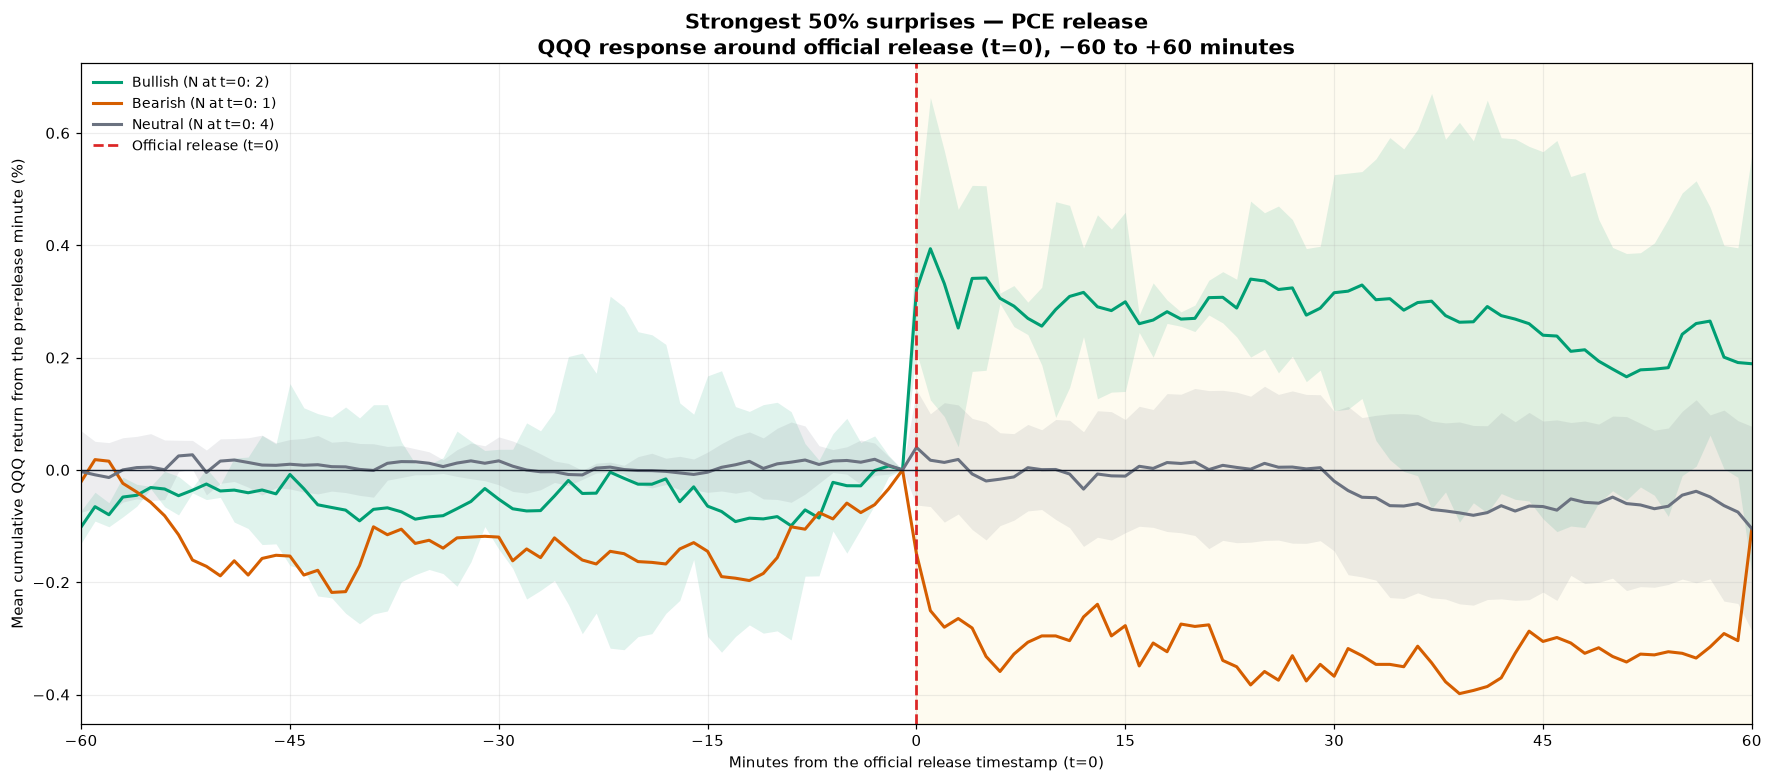

Saved official-centered strongest-50% +/-60-minute figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_PCE_RELEASE_top50pct_surprise_official_pm60min.png


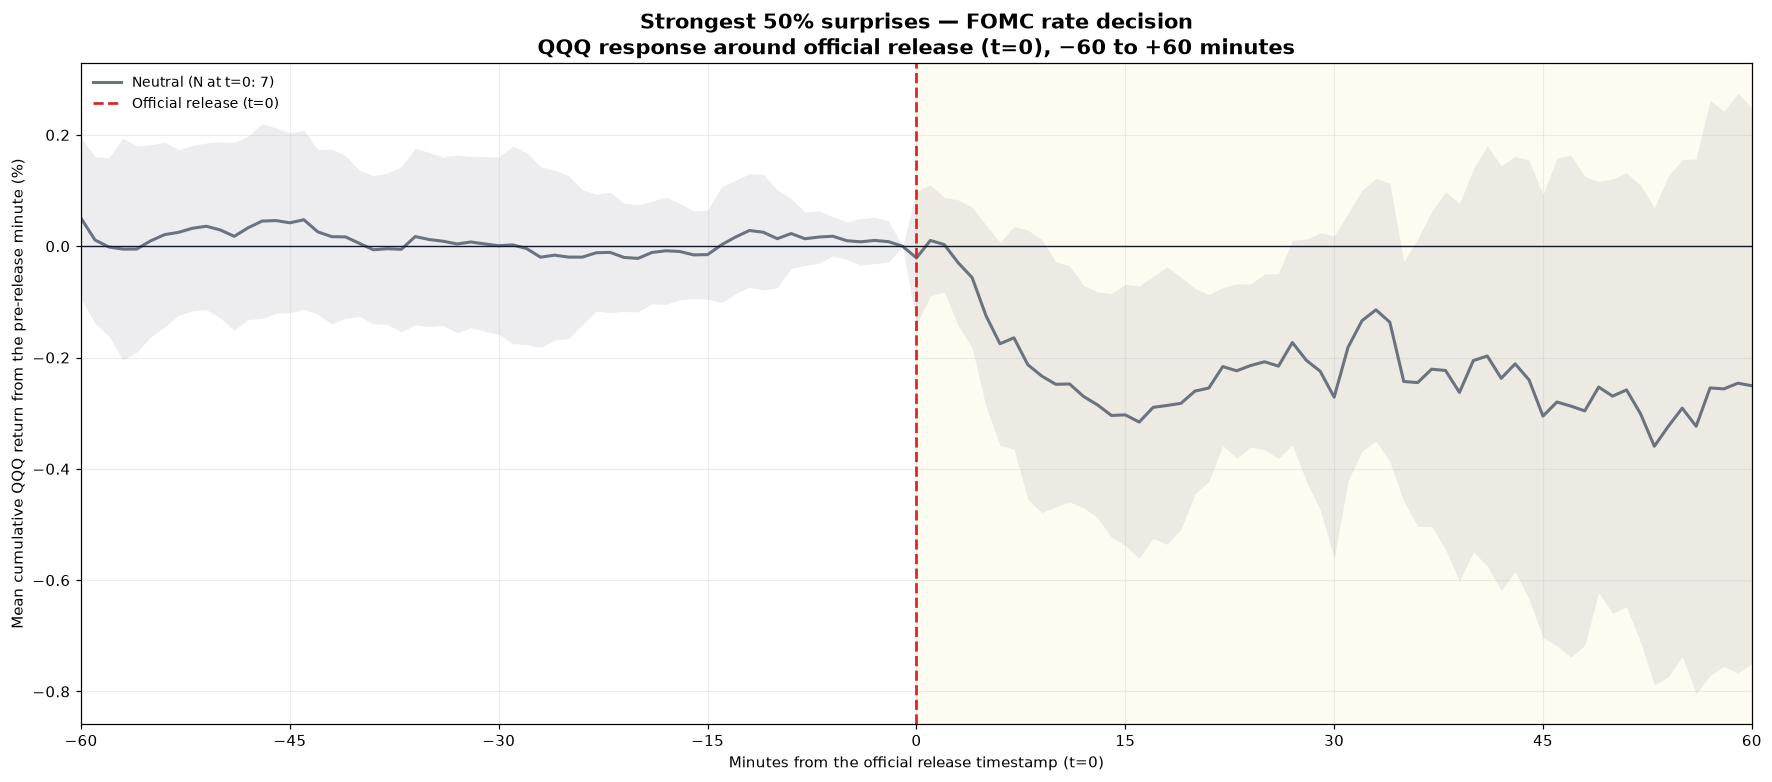

Saved official-centered strongest-50% +/-60-minute figure to: C:\Users\Jerry Cai\Desktop\NLP_Final_Assignment\outputs\macro_event_identification_3y\QQQ_3y_extended_FOMC_RATE_DECISION_top50pct_surprise_official_pm60min.png


In [26]:
THREE_YEAR_DIR = ROOT / "outputs" / "macro_event_identification_3y"
three_year_daily_df = pd.read_csv(THREE_YEAR_DIR / "macro_event_surprises_by_release_date.csv")
three_year_minute_df = pd.read_csv(THREE_YEAR_DIR / "QQQ_event_intraday_1min_extended.csv")
three_year_daily_df["release_date"] = pd.to_datetime(three_year_daily_df["release_date"], errors="coerce")
three_year_minute_df["release_date"] = pd.to_datetime(three_year_minute_df["release_date"], errors="coerce")
three_year_minute_df["earliest_news_datetime_utc"] = pd.to_datetime(three_year_minute_df["earliest_news_datetime_et"], errors="coerce", utc=True)

three_year_event_rows = three_year_minute_df[[
    "event_ids", "event_types", "equity_label", "release_date",
    "earliest_news_datetime_utc", "event_surprise_mean"
]].drop_duplicates("event_ids")
three_year_coverage = (
    three_year_event_rows.groupby(["event_types", "equity_label"], observed=True)
    .agg(events=("event_ids", "size"), first_release=("release_date", "min"), last_release=("release_date", "max"))
    .reset_index()
)
display(three_year_coverage)
print(f"Three-year tradable events: {three_year_event_rows['event_ids'].nunique()}")
print(f"Extended-hours minute rows: {len(three_year_minute_df):,}")

def aggregate_three_year_sample(minute_df):
    result = (
        minute_df.dropna(subset=["relative_event_minute", "return_from_pre_news_price_pct"])
        .groupby(["event_types", "equity_label", "relative_event_minute"], observed=True)
        .agg(
            mean_cumulative_return_pct=("return_from_pre_news_price_pct", "mean"),
            median_cumulative_return_pct=("return_from_pre_news_price_pct", "median"),
            std_cumulative_return_pct=("return_from_pre_news_price_pct", "std"),
            mean_minute_return_pct=("minute_return_pct", "mean"),
            event_count=("event_ids", "nunique"),
        ).reset_index()
    )
    result["relative_event_hour"] = result["relative_event_minute"] / 60
    result["sem_cumulative_return_pct"] = result["std_cumulative_return_pct"] / np.sqrt(result["event_count"])
    result["ci95_lower"] = result["mean_cumulative_return_pct"] - 1.96 * result["sem_cumulative_return_pct"]
    result["ci95_upper"] = result["mean_cumulative_return_pct"] + 1.96 * result["sem_cumulative_return_pct"]
    return result

def draw_three_year_panel(ax, aggregate_df, event_type, xlim_hours=(-36, 36)):
    event_plot = aggregate_df.loc[aggregate_df["event_types"].eq(event_type)].copy()
    ax.axvspan(0, xlim_hours[1], color="#FEF3C7", alpha=0.25, zorder=0)
    for equity_label in EXT_LABEL_NAMES:
        group_plot = event_plot.loc[event_plot["equity_label"].eq(equity_label)].sort_values("relative_event_minute")
        group_plot = group_plot.loc[group_plot["relative_event_hour"].between(*xlim_hours)]
        if group_plot.empty:
            continue
        near_zero = group_plot.loc[group_plot["relative_event_minute"].between(-1, 1), "event_count"]
        n_at_news = int(near_zero.max()) if not near_zero.empty else 0
        gap_group = group_plot["relative_event_minute"].diff().fillna(1).ne(1).cumsum()
        label_used = False
        for _, segment in group_plot.groupby(gap_group):
            x = segment["relative_event_hour"].to_numpy()
            ax.plot(x, segment["mean_cumulative_return_pct"].to_numpy(), color=EXT_LABEL_COLORS[equity_label], linewidth=1.6, label=(f"{EXT_LABEL_NAMES[equity_label]} (N at t=0: {n_at_news})" if not label_used else None))
            valid_ci = segment["event_count"].ge(2)
            if valid_ci.any():
                ax.fill_between(x, segment["ci95_lower"].to_numpy(), segment["ci95_upper"].to_numpy(), where=valid_ci.to_numpy(), color=EXT_LABEL_COLORS[equity_label], alpha=0.10, linewidth=0)
            label_used = True
    ax.axvline(0, color="#DC2626", linestyle="--", linewidth=1.5)
    ax.axhline(0, color="#111827", linewidth=0.8)
    ax.set_xlim(*xlim_hours)
    ax.set_ylabel("Mean cumulative QQQ return (%)")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, fontsize=9, loc="best")

three_year_event_time_avg = aggregate_three_year_sample(three_year_minute_df)
three_year_event_time_avg.to_csv(THREE_YEAR_DIR / "QQQ_3y_event_time_cumulative_return.csv", index=False, encoding="utf-8-sig")
THREE_YEAR_FULL_FIGURE_PATHS = {}
for event_type in EXT_EVENT_ORDER:
    fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
    draw_three_year_panel(ax, three_year_event_time_avg, event_type)
    ax.set_xlabel("Hours from each event's earliest news timestamp (t=0)")
    ax.set_title(f"Three-year QQQ response: {EXT_EVENT_TITLES[event_type]}\nFull T-1 / event-day / T+1 window (extended hours included)", fontsize=15, fontweight="bold")
    figure_path = THREE_YEAR_DIR / f"QQQ_3y_extended_{event_type}_news_centered_full.png"
    fig.savefig(figure_path, dpi=220, bbox_inches="tight")
    THREE_YEAR_FULL_FIGURE_PATHS[event_type] = figure_path
    plt.show()
    print(f"Saved three-year full-sample figure to: {figure_path}")

three_year_ranked_events = three_year_event_rows.dropna(subset=["event_surprise_mean"]).copy()
three_year_ranked_events["abs_event_surprise"] = three_year_ranked_events["event_surprise_mean"].abs()
three_year_group_keys = ["event_types", "equity_label"]
three_year_ranked_events["group_event_count"] = three_year_ranked_events.groupby(three_year_group_keys, observed=True)["event_ids"].transform("size")
three_year_ranked_events = three_year_ranked_events.sort_values(three_year_group_keys + ["abs_event_surprise", "earliest_news_datetime_utc", "event_ids"], ascending=[True, True, False, True, True]).reset_index(drop=True)
three_year_ranked_events["surprise_rank_within_group"] = three_year_ranked_events.groupby(three_year_group_keys, observed=True).cumcount() + 1
three_year_ranked_events["events_to_keep"] = (three_year_ranked_events["group_event_count"] + 1) // 2
three_year_top50_events = three_year_ranked_events.loc[three_year_ranked_events["surprise_rank_within_group"] <= three_year_ranked_events["events_to_keep"]].copy()
three_year_top50_minute_df = three_year_minute_df.merge(three_year_top50_events[["event_ids", "abs_event_surprise", "surprise_rank_within_group"]], on="event_ids", how="inner", validate="many_to_one")
three_year_top50_avg = aggregate_three_year_sample(three_year_top50_minute_df)
three_year_top50_events.to_csv(THREE_YEAR_DIR / "QQQ_3y_top50pct_surprise_selected_events.csv", index=False, encoding="utf-8-sig")
three_year_top50_avg.to_csv(THREE_YEAR_DIR / "QQQ_3y_top50pct_surprise_event_time_cumulative_return.csv", index=False, encoding="utf-8-sig")
display(three_year_ranked_events.groupby(three_year_group_keys, observed=True).agg(total_events=("event_ids", "size"), events_kept=("events_to_keep", "first")).reset_index())

THREE_YEAR_TOP50_FIGURE_PATHS = {}
for event_type in EXT_EVENT_ORDER:
    fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
    draw_three_year_panel(ax, three_year_top50_avg, event_type)
    ax.set_xlabel("Hours from each event's earliest news timestamp (t=0)")
    ax.set_title(f"Strongest 50% surprises: {EXT_EVENT_TITLES[event_type]}\nTop half within each direction group; full T-1 / event-day / T+1 window", fontsize=15, fontweight="bold")
    figure_path = THREE_YEAR_DIR / f"QQQ_3y_extended_{event_type}_top50pct_surprise_full.png"
    fig.savefig(figure_path, dpi=220, bbox_inches="tight")
    THREE_YEAR_TOP50_FIGURE_PATHS[event_type] = figure_path
    plt.show()
    print(f"Saved three-year strongest-50% figure to: {figure_path}")

# Zoomed event study: strongest 50% surprises, one hour before/after the exact news minute.
three_year_top50_pm60_avg = three_year_top50_avg.loc[
    three_year_top50_avg["relative_event_minute"].between(-60, 60)
].copy()
three_year_top50_pm60_avg.to_csv(
    THREE_YEAR_DIR / "QQQ_3y_top50pct_surprise_pm60min_cumulative_return.csv",
    index=False, encoding="utf-8-sig",
)

def draw_three_year_pm60_panel(ax, aggregate_df, event_type):
    event_plot = aggregate_df.loc[aggregate_df["event_types"].eq(event_type)].copy()
    ax.axvspan(0, 60, color="#FEF3C7", alpha=0.25, zorder=0)
    for equity_label in EXT_LABEL_NAMES:
        group_plot = event_plot.loc[event_plot["equity_label"].eq(equity_label)].sort_values("relative_event_minute")
        if group_plot.empty:
            continue
        near_zero = group_plot.loc[group_plot["relative_event_minute"].between(-1, 1), "event_count"]
        n_at_news = int(near_zero.max()) if not near_zero.empty else 0
        gap_group = group_plot["relative_event_minute"].diff().fillna(1).ne(1).cumsum()
        label_used = False
        for _, segment in group_plot.groupby(gap_group):
            x = segment["relative_event_minute"].to_numpy()
            ax.plot(
                x, segment["mean_cumulative_return_pct"].to_numpy(),
                color=EXT_LABEL_COLORS[equity_label], linewidth=2.0,
                label=(f"{EXT_LABEL_NAMES[equity_label]} (N at t=0: {n_at_news})" if not label_used else None),
            )
            valid_ci = segment["event_count"].ge(2)
            if valid_ci.any():
                ax.fill_between(
                    x, segment["ci95_lower"].to_numpy(), segment["ci95_upper"].to_numpy(),
                    where=valid_ci.to_numpy(), color=EXT_LABEL_COLORS[equity_label], alpha=0.12, linewidth=0,
                )
            label_used = True
    ax.axvline(0, color="#DC2626", linestyle="--", linewidth=1.8, label="Earliest news (t=0)")
    ax.axhline(0, color="#111827", linewidth=0.9)
    ax.set_xlim(-60, 60)
    ax.set_xticks(np.arange(-60, 61, 15))
    ax.set_xlabel("Minutes from each event's earliest news timestamp (t=0)")
    ax.set_ylabel("Mean cumulative QQQ return from pre-news price (%)")
    ax.grid(axis="both", alpha=0.22)
    ax.legend(frameon=False, fontsize=9, loc="best")

THREE_YEAR_TOP50_PM60_FIGURE_PATHS = {}
for event_type in EXT_EVENT_ORDER:
    fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
    draw_three_year_pm60_panel(ax, three_year_top50_pm60_avg, event_type)
    ax.set_title(
        f"Strongest 50% surprises: {EXT_EVENT_TITLES[event_type]}\nQQQ response from 60 minutes before to 60 minutes after the earliest news",
        fontsize=15, fontweight="bold",
    )
    figure_path = THREE_YEAR_DIR / f"QQQ_3y_extended_{event_type}_top50pct_surprise_pm60min.png"
    fig.savefig(figure_path, dpi=220, bbox_inches="tight")
    THREE_YEAR_TOP50_PM60_FIGURE_PATHS[event_type] = figure_path
    plt.show()
    print(f"Saved strongest-50% +/-60-minute figure to: {figure_path}")

# Official-release-centered event study for the same strongest-50% sample.
three_year_top50_official_parts = []
for event_id, event_frame in three_year_top50_minute_df.groupby("event_ids", observed=True):
    event_frame = event_frame.copy()
    event_frame["datetime_utc"] = pd.to_datetime(event_frame["datetime_et"], errors="coerce", utc=True)
    official_time = pd.to_datetime(event_frame["official_release_datetime_et"].iloc[0], errors="coerce")
    if pd.isna(official_time):
        continue
    if official_time.tzinfo is None:
        official_time = official_time.tz_localize("America/New_York").tz_convert("UTC")
    else:
        official_time = official_time.tz_convert("UTC")
    event_frame = event_frame.sort_values("datetime_utc")
    pre_release = event_frame.loc[event_frame["datetime_utc"] < official_time]
    if pre_release.empty:
        continue
    reference_row = pre_release.iloc[-1]
    reference_price = float(reference_row["close"])
    event_frame["relative_official_minute"] = (
        (event_frame["datetime_utc"] - official_time).dt.total_seconds() / 60
    ).round().astype("Int64")
    event_frame["official_reference_datetime_et"] = reference_row["datetime_et"]
    event_frame["official_reference_price"] = reference_price
    event_frame["return_from_pre_official_price_pct"] = 100 * (event_frame["close"] / reference_price - 1)
    three_year_top50_official_parts.append(event_frame)

three_year_top50_official_minute_df = pd.concat(three_year_top50_official_parts, ignore_index=True)
three_year_top50_official_pm60 = three_year_top50_official_minute_df.loc[
    three_year_top50_official_minute_df["relative_official_minute"].between(-60, 60)
].copy()
three_year_top50_official_avg = (
    three_year_top50_official_pm60
    .groupby(["event_types", "equity_label", "relative_official_minute"], observed=True)
    .agg(
        mean_cumulative_return_pct=("return_from_pre_official_price_pct", "mean"),
        median_cumulative_return_pct=("return_from_pre_official_price_pct", "median"),
        std_cumulative_return_pct=("return_from_pre_official_price_pct", "std"),
        event_count=("event_ids", "nunique"),
    ).reset_index()
)
three_year_top50_official_avg["sem_cumulative_return_pct"] = (
    three_year_top50_official_avg["std_cumulative_return_pct"] / np.sqrt(three_year_top50_official_avg["event_count"])
)
three_year_top50_official_avg["ci95_lower"] = (
    three_year_top50_official_avg["mean_cumulative_return_pct"] - 1.96 * three_year_top50_official_avg["sem_cumulative_return_pct"]
)
three_year_top50_official_avg["ci95_upper"] = (
    three_year_top50_official_avg["mean_cumulative_return_pct"] + 1.96 * three_year_top50_official_avg["sem_cumulative_return_pct"]
)
three_year_top50_official_avg.to_csv(
    THREE_YEAR_DIR / "QQQ_3y_top50pct_surprise_official_pm60min_cumulative_return.csv",
    index=False, encoding="utf-8-sig",
)

def draw_three_year_official_pm60_panel(ax, aggregate_df, event_type):
    event_plot = aggregate_df.loc[aggregate_df["event_types"].eq(event_type)].copy()
    ax.axvspan(0, 60, color="#FEF3C7", alpha=0.25, zorder=0)
    for equity_label in EXT_LABEL_NAMES:
        group_plot = event_plot.loc[event_plot["equity_label"].eq(equity_label)].sort_values("relative_official_minute")
        if group_plot.empty:
            continue
        at_release = group_plot.loc[group_plot["relative_official_minute"].eq(0), "event_count"]
        n_at_release = int(at_release.max()) if not at_release.empty else 0
        gap_group = group_plot["relative_official_minute"].diff().fillna(1).ne(1).cumsum()
        label_used = False
        for _, segment in group_plot.groupby(gap_group):
            x = segment["relative_official_minute"].astype(float).to_numpy()
            ax.plot(
                x, segment["mean_cumulative_return_pct"].to_numpy(),
                color=EXT_LABEL_COLORS[equity_label], linewidth=2.0,
                label=(f"{EXT_LABEL_NAMES[equity_label]} (N at t=0: {n_at_release})" if not label_used else None),
            )
            valid_ci = segment["event_count"].ge(2)
            if valid_ci.any():
                ax.fill_between(
                    x, segment["ci95_lower"].to_numpy(), segment["ci95_upper"].to_numpy(),
                    where=valid_ci.to_numpy(), color=EXT_LABEL_COLORS[equity_label], alpha=0.12, linewidth=0,
                )
            label_used = True
    ax.axvline(0, color="#DC2626", linestyle="--", linewidth=1.8, label="Official release (t=0)")
    ax.axhline(0, color="#111827", linewidth=0.9)
    ax.set_xlim(-60, 60)
    ax.set_xticks(np.arange(-60, 61, 15))
    ax.set_xlabel("Minutes from the official release timestamp (t=0)")
    ax.set_ylabel("Mean cumulative QQQ return from the pre-release minute (%)")
    ax.grid(axis="both", alpha=0.22)
    ax.legend(frameon=False, fontsize=9, loc="best")

THREE_YEAR_TOP50_OFFICIAL_PM60_FIGURE_PATHS = {}
for event_type in EXT_EVENT_ORDER:
    fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
    draw_three_year_official_pm60_panel(ax, three_year_top50_official_avg, event_type)
    ax.set_title(
        f"Strongest 50% surprises — {EXT_EVENT_TITLES[event_type]}\nQQQ response around official release (t=0), −60 to +60 minutes",
        fontsize=14, fontweight="bold",
    )
    figure_path = THREE_YEAR_DIR / f"QQQ_3y_extended_{event_type}_top50pct_surprise_official_pm60min.png"
    fig.savefig(figure_path, dpi=220, bbox_inches="tight")
    THREE_YEAR_TOP50_OFFICIAL_PM60_FIGURE_PATHS[event_type] = figure_path
    plt.show()
    print(f"Saved official-centered strongest-50% +/-60-minute figure to: {figure_path}")